<p class="lead">The linear model is the workhorse of quantitative science and the ancestor of every method in Block D. It is also the only model in this course whose parameters can be read as statements about the world rather than as machinery for prediction — which is why it is simultaneously the most useful and the most abused tool a thesis student has. This unit builds ordinary least squares from the normal equations, reads a regression table line by line, and then spends most of its length on the diagnostics that decide whether the table may be believed: residual structure, leverage and influence, multicollinearity, and the chance correlation that appears whenever there are too many descriptors for too few compounds. The applied thread is a <strong>Hansch-type QSAR</strong> on a congeneric series of ROCK1 inhibitors, which fails honestly and instructively; the unit then adds logistic regression with calibration, the ridge/lasso/elastic-net family as an explicit bias–variance trade-off, formal model comparison, and blocking as the cure for a confounded comparison. It closes on the question that should be asked before any model is fitted: are we explaining, or are we predicting?</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad construye el modelo lineal desde las ecuaciones normales y con statsmodels, y enseña a leer una tabla de regresión: coeficientes, errores estándar, intervalos, R² y R² ajustado. Se tratan en profundidad los diagnósticos (gráficos de residuos, apalancamiento, distancia de Cook, multicolinealidad y VIF), las transformaciones, los predictores categóricos y las interacciones, y el ANOVA como caso particular del modelo lineal. Se reproduce un QSAR de tipo Hansch sobre una serie congenérica de inhibidores de ROCK1 y se controla la correlación por azar (Topliss-Costello) mediante aleatorización de la variable respuesta. Se ajusta una regresión logística (razones de momios, separación, calibración), se comparan cresta, lazo y red elástica como compromisos sesgo-varianza con penalización elegida por validación cruzada y estabilidad por bootstrap, y se comparan modelos con R² ajustado, AIC, BIC y pruebas de razón de verosimilitud. Finalmente se usa el diseño pareado de la matriz de expresión para ilustrar el bloqueo y la confusión, y se distingue el modelado explicativo del predictivo.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Derive and compute ordinary least squares from the normal equations, and interpret coefficients, standard errors, confidence intervals, R² and adjusted R².</li>
<li>Diagnose a fitted model with residual plots, leverage, Cook's distance and variance inflation factors, and say what each diagnostic can and cannot detect.</li>
<li>Use transformations, categorical predictors and interactions, and recognise ANOVA as a linear model.</li>
<li>Fit a Hansch-type QSAR on a congeneric series, state the series-selection rule, and control for chance correlation by response randomisation.</li>
<li>Fit and interpret logistic regression: likelihood, odds ratios, separation, and calibration of predicted probabilities.</li>
<li>Explain ridge, lasso and elastic net as bias–variance trade-offs, choose the penalty by cross-validation, and assess the stability of lasso selection by bootstrap.</li>
<li>Compare models with adjusted R², AIC, BIC and likelihood-ratio tests, and know what each comparison assumes.</li>
<li>Use a blocking factor to remove a confound, and distinguish explanatory from predictive modelling.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read linearly, running each cell; then refit the central model after removing one descriptor and watch every other coefficient move — that single experiment teaches multicollinearity better than any paragraph. In Google Colab run <code>!pip install rdkit</code> once before the setup cell; NumPy, pandas, SciPy, statsmodels<sup class="c"><a href="#r1">[1]</a></sup>, scikit-learn and Matplotlib are already there. This unit assumes <a href="../U7_Estimation/index.html">Unit 7</a> (standard errors, intervals, bootstrap) and <a href="../U8_Hypothesis_Testing/index.html">Unit 8</a> (tests, effect sizes, multiplicity).</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit
from pathlib import Path
import urllib.request
import numpy as np, pandas as pd, scipy, matplotlib, matplotlib.pyplot as plt
import statsmodels, statsmodels.api as sm, statsmodels.formula.api as smf
import sklearn
from scipy import stats
np.random.seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

numpy 2.4.6 | pandas 3.0.3 | statsmodels 0.14.6 | scikit-learn 1.9.0 | scipy 1.17.1


In [2]:
# The modelling table and the eleven interpretable descriptors used throughout.
rock = load_data("rock1_chembl_curated.csv")
exact = rock.loc[~rock["censored"]].reset_index(drop=True)
DESC = ["MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB",
        "AromaticRings", "RingCount", "HeavyAtoms", "FractionCSP3", "QED"]
counts = exact["scaffold_smiles"].value_counts()
big = counts[counts >= 30]
print("compounds with an exact potency value :", len(exact))
print("distinct Bemis-Murcko scaffolds       :", exact["scaffold_smiles"].nunique())
print("scaffold families with >= 30 compounds:", len(big), "-> sizes", list(big.values))
print("\ndescriptor summary (exact subset):")
print(exact[DESC].describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

compounds with an exact potency value : 2764
distinct Bemis-Murcko scaffolds       : 1218
scaffold families with >= 30 compounds: 5 -> sizes [np.int64(207), np.int64(59), np.int64(43), np.int64(38), np.int64(33)]

descriptor summary (exact subset):
       MolWt  MolLogP    TPSA    HBD    HBA   RotB  AromaticRings  RingCount  HeavyAtoms  FractionCSP3   QED
mean  381.59     3.52   86.41   2.31   4.77   4.71           3.47       4.07       27.76          0.21  0.57
std    80.25     1.14   26.02   1.03   1.51   2.10           0.86       1.03        5.88          0.13  0.17
min   133.15    -1.27   12.89   0.00   1.00   0.00           1.00       1.00       10.00          0.00  0.04
max   915.85     7.54  382.54  16.00  12.00  18.00           7.00      11.00       67.00          0.62  0.94


## 1. What a linear model says

A linear model asserts that the expected value of a response is a weighted sum of predictors:

$$y_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip} + \varepsilon_i,\qquad \varepsilon_i \stackrel{\text{iid}}{\sim} \mathcal{N}(0,\sigma^2).$$

"Linear" refers to the **coefficients**, not to the predictors: $y = \beta_0 + \beta_1 x + \beta_2 x^2$ is a linear model, and so is a model in log x or in an interaction term $x_1x_2$. The assumptions that matter, in decreasing order of how much damage their violation does:

1. **Independence** of the errors. Violated by repeated measurements of the same patient, frames of the same trajectory, compounds from the same series. No amount of data fixes it; the model must be changed (blocking, §11).
2. **Correct functional form** — the mean really is a weighted sum of these predictors. Violated silently; residual plots are the detector (§4).
3. **Homoscedasticity** — constant error variance. Inflates or deflates standard errors when violated.
4. **Normality of the errors** — needed only for exact small-sample inference; irrelevant for large n thanks to the central limit theorem of Unit 7.

<div class="box bridge"><h4>Domain context — congeneric series and Hansch analysis</h4>
<p>A <strong>congeneric series</strong> is a family of molecules sharing one core structure (the <strong>scaffold</strong>) and differing only in the substituents hung off it. Medicinal chemists work this way: once a promising core is found, dozens of analogues are made by varying one position at a time. In 1962–1964 Corwin Hansch and Toshio Fujita proposed that, within such a series, biological potency can be written as a linear function of a few physicochemical properties of the substituents — lipophilicity (log P), an electronic term and a steric term<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>. That proposal created <strong>QSAR</strong> (quantitative structure–activity relationship) and it is, mathematically, nothing but multiple linear regression. Its classical practice rules — use a congeneric series, use at least five compounds per descriptor, avoid collinear descriptors, check for chance correlation<sup class="c"><a href="#r4">[4]</a></sup> — are exactly the linear-model diagnostics of this unit, discovered independently by chemists. The descriptors available in our table are whole-molecule properties computed by RDKit: molecular weight, calculated log P, topological polar surface area (TPSA, a proxy for membrane permeability), counts of hydrogen-bond donors and acceptors and of rotatable bonds, ring counts, the fraction of sp<sup>3</sup> carbons (a measure of three-dimensionality) and QED, a composite drug-likeness score between 0 and 1. The <strong>Bemis–Murcko scaffold</strong><sup class="c"><a href="#r5">[5]</a></sup> is the computable definition of "the core" used to group compounds into series, and the data themselves come from ChEMBL<sup class="c"><a href="#r32">[32]</a></sup>, curated in Unit 6. The three-dimensional descendant of Hansch analysis, comparative molecular field analysis (CoMFA)<sup class="c"><a href="#r29">[29]</a></sup>, replaces the handful of descriptors with thousands of interaction-energy values on a grid and then regularises — the same bias–variance problem as §9, forty years earlier.</p></div>

## 2. Ordinary least squares from the normal equations

OLS chooses the coefficients that minimise the sum of squared residuals $\lVert y - X\beta \rVert^2$. Differentiating and setting the gradient to zero gives the **normal equations** $X^{\mathsf T}X\hat\beta = X^{\mathsf T}y$, so

$$\hat\beta = (X^{\mathsf T}X)^{-1}X^{\mathsf T}y, \qquad \widehat{\operatorname{Var}}(\hat\beta) = \hat\sigma^{2}(X^{\mathsf T}X)^{-1},\qquad \hat\sigma^{2} = \frac{\lVert y - X\hat\beta\rVert^{2}}{n-p-1}.$$

### 2.1 Worked by hand

Take five compounds with calculated log P values 2.0, 3.0, 4.0, 5.0, 6.0 and potencies 6.0, 6.6, 7.0, 7.1, 7.3. With a single predictor the normal equations reduce to the familiar formulas.

Mean of x = (2+3+4+5+6)/5 = 4.0; mean of y = (6.0+6.6+7.0+7.1+7.3)/5 = 34.0/5 = 6.8.

| x | y | x − x̄ | y − ȳ | (x−x̄)(y−ȳ) | (x−x̄)² |
|---|---|---|---|---|---|
| 2.0 | 6.0 | −2 | −0.8 | 1.60 | 4 |
| 3.0 | 6.6 | −1 | −0.2 | 0.20 | 1 |
| 4.0 | 7.0 | 0 | +0.2 | 0.00 | 0 |
| 5.0 | 7.1 | +1 | +0.3 | 0.30 | 1 |
| 6.0 | 7.3 | +2 | +0.5 | 1.00 | 4 |
| | | | **Σ** | **3.10** | **10** |

Slope $\hat\beta_1 = 3.10/10 = 0.310$; intercept $\hat\beta_0 = 6.8 - 0.310 \times 4.0 = 5.560$.

Fitted values: 6.180, 6.490, 6.800, 7.110, 7.420. Residuals: −0.180, +0.110, +0.200, −0.010, −0.120. Residual sum of squares = 0.0324 + 0.0121 + 0.0400 + 0.0001 + 0.0144 = **0.0990**. Total sum of squares = 0.64 + 0.04 + 0.04 + 0.09 + 0.25 = **1.0600**, so $R^2 = 1 - 0.0990/1.0600 = 0.9066$.

Residual standard error $\hat\sigma = \sqrt{0.0990/3} = 0.1817$; the standard error of the slope is $\hat\sigma/\sqrt{\sum(x-\bar x)^2} = 0.1817/\sqrt{10} = 0.0575$, giving $t = 0.310/0.0575 = 5.39$ on 3 degrees of freedom.

In [3]:
# The hand calculation three ways: formulas, the normal equations, statsmodels.
x = np.array([2.0, 3.0, 4.0, 5.0, 6.0]); yv = np.array([6.0, 6.6, 7.0, 7.1, 7.3])
b1 = ((x - x.mean()) * (yv - yv.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = yv.mean() - b1 * x.mean()
X = np.column_stack([np.ones(len(x)), x])
beta_ne = np.linalg.solve(X.T @ X, X.T @ yv)                 # the normal equations, solved directly
fit = sm.OLS(yv, X).fit()
resid = yv - X @ beta_ne
sigma2 = (resid ** 2).sum() / (len(x) - 2)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
print("by hand          : b0 = %.4f, b1 = %.4f" % (b0, b1))
print("normal equations : b0 = %.4f, b1 = %.4f" % tuple(beta_ne))
print("statsmodels      : b0 = %.4f, b1 = %.4f" % tuple(fit.params))
print("RSS %.4f | TSS %.4f | R2 %.4f (statsmodels %.4f)"
      % ((resid ** 2).sum(), ((yv - yv.mean()) ** 2).sum(),
         1 - (resid ** 2).sum() / ((yv - yv.mean()) ** 2).sum(), fit.rsquared))
print("sigma_hat %.4f | SE(b1) by hand %.4f | statsmodels %.4f | t = %.2f"
      % (np.sqrt(sigma2), se[1], fit.bse[1], fit.tvalues[1]))
print("95%% CI for the slope: [%.4f, %.4f]" % tuple(fit.conf_int()[1]))

by hand          : b0 = 5.5600, b1 = 0.3100
normal equations : b0 = 5.5600, b1 = 0.3100
statsmodels      : b0 = 5.5600, b1 = 0.3100
RSS 0.0990 | TSS 1.0600 | R2 0.9066 (statsmodels 0.9066)
sigma_hat 0.1817 | SE(b1) by hand 0.0574 | statsmodels 0.0574 | t = 5.40
95% CI for the slope: [0.1272, 0.4928]


Every number from the hand calculation is reproduced to four decimals. This is worth doing once, because it makes the regression table stop being an oracle: the slope is a ratio of two sums, the standard error is a scaled diagonal element of an inverted matrix, and the t statistic is their quotient.

<div class="box warn"><h4>Never invert the matrix in production code</h4>
<p><code>np.linalg.solve(X.T @ X, X.T @ y)</code> is used above for transparency. Real implementations — statsmodels, scikit-learn — use a QR or SVD decomposition of X, which is numerically far more stable when the columns are nearly collinear (§5). Computing <code>inv(X.T @ X)</code> on a descriptor matrix with correlated columns can lose most of the available precision.</p></div>

## 3. Reading a regression table

The next cell fits the Hansch-type model on a real congeneric series. The **series-selection rule**, stated explicitly because it is a modelling decision a referee will ask about: among compounds with an exact (non-censored) measurement, group by Bemis–Murcko generic scaffold, keep families with at least 30 members, and take the largest. That family has about 207 compounds for 11 descriptors — about 19 compounds per descriptor, comfortably above the classical requirement of five<sup class="c"><a href="#r4">[4]</a></sup>.

In [4]:
# A Hansch-type QSAR on the largest congeneric series.
series = exact.loc[exact.scaffold_smiles == counts.index[0]].reset_index(drop=True)
y = series["pActivity"].to_numpy()
Xs = sm.add_constant(series[DESC])
hansch = sm.OLS(y, Xs).fit()
print("series size n = %d | descriptors p = %d | compounds per descriptor = %.1f"
      % (len(series), len(DESC), len(series) / len(DESC)))
print("R2 = %.3f | adjusted R2 = %.3f | F = %.2f on (%d, %d) df | p(F) = %.4f"
      % (hansch.rsquared, hansch.rsquared_adj, hansch.fvalue, hansch.df_model, hansch.df_resid, hansch.f_pvalue))
print("residual standard error = %.3f log units (target SD = %.3f)"
      % (np.sqrt(hansch.mse_resid), y.std(ddof=1)))
print()
print(hansch.summary2().tables[1].round(4).to_string())

series size n = 207 | descriptors p = 11 | compounds per descriptor = 18.8
R2 = 0.078 | adjusted R2 = 0.036 | F = 1.86 on (9, 197) df | p(F) = 0.0593
residual standard error = 0.797 log units (target SD = 0.812)

                Coef.  Std.Err.       t   P>|t|   [0.025   0.975]
MolWt          0.0047    0.0079  0.6007  0.5487  -0.0108   0.0202
MolLogP        0.1075    0.2301  0.4670  0.6410  -0.3464   0.5613
TPSA          -0.0148    0.0121 -1.2292  0.2205  -0.0386   0.0090
HBD            0.5532    0.3376  1.6386  0.1029  -0.1126   1.2190
HBA            0.3560    0.2019  1.7635  0.0794  -0.0421   0.7540
RotB           0.2663    0.1600  1.6642  0.0977  -0.0493   0.5818
AromaticRings  0.4735    0.9583  0.4941  0.6218  -1.4163   2.3633
RingCount      0.4735    0.9583  0.4941  0.6218  -1.4163   2.3633
HeavyAtoms    -0.0991    0.1278 -0.7750  0.4393  -0.3511   0.1530
FractionCSP3  -5.0593    2.5945 -1.9500  0.0526 -10.1759   0.0573
QED            4.4764    3.9140  1.1437  0.2541  -3.2422  12.

Read the table in this order, and in no other:

1. **The F test and R².** Here R² is about 0.08 and the overall F test gives p ≈ 0.06. The eleven whole-molecule descriptors together explain less than a tenth of the potency variation inside this series, and the model as a whole is not significant. **This is the result, and it is a real one.**
2. **Only then, the coefficients.** Reading individual coefficients from a model that does not pass its own F test is the most common way to generate a false QSAR narrative. Several coefficients here have p-values near 0.05 — which is exactly what eleven predictors produce on noise.
3. **The residual standard error**, about 0.79 log units against a target standard deviation of about 0.81 — the model has barely reduced the unexplained variation.

The chemistry behind the failure is worth stating, because students usually assume the code is wrong. Inside an optimised congeneric series, molecules have nearly the same size, lipophilicity and polarity by construction; what differs is *where* a substituent sits and what specific contact it makes with the protein. Whole-molecule descriptors are blind to that. Classical Hansch analysis used substituent constants (Hammett σ, Hansch π, Taft E<sub>s</sub>) measured per substituent position, not whole-molecule properties, which is precisely the difference. The lesson for the thesis: **a QSAR that fails to fit is not a failure of the student; it is information about the descriptors.**

The residual standard error also deserves a comparison the field rarely makes: Unit 7 estimated the experimental noise floor of this dataset at roughly 0.4 log units, and independent analyses of public bioactivity data reach similar figures<sup class="c"><a href="#r33">[33]</a></sup>. A model whose residual error is 0.79 log units is therefore about twice as far from the labels as the labels are from each other — there is room to improve, but not unlimited room<sup class="c"><a href="#r30">[30]</a></sup>.

observed range 5.39 - 9.70, predicted range 6.76 - 7.86  <- the model barely varies
with 60 random predictors on 207 compounds: R2 = 0.316 but adjusted R2 = 0.035
the real model with 11 chemical descriptors: R2 = 0.078, adjusted R2 = 0.036


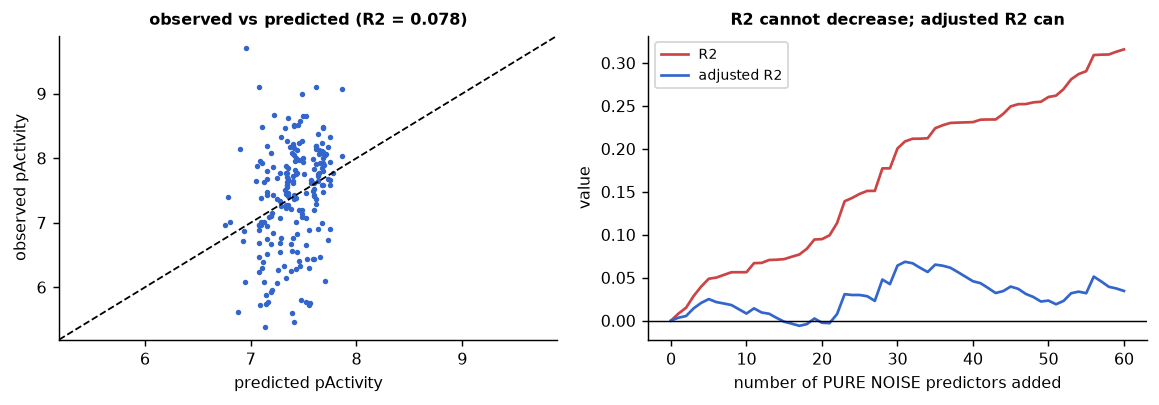

In [5]:
# What the failed model looks like, and what R2 inflation looks like.
pred = hansch.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.2))
axes[0].plot(pred, y, ".", ms=4, color="#36c")
lims = [min(pred.min(), y.min()) - 0.2, max(pred.max(), y.max()) + 0.2]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("predicted pActivity"); axes[0].set_ylabel("observed pActivity")
axes[0].set_title("observed vs predicted (R2 = %.3f)" % hansch.rsquared, fontsize=9)
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
r2_grow, r2_adj_grow = [], []
Xgrow = np.ones((len(y), 1))
for k in range(0, 61):
    if k > 0:
        Xgrow = np.column_stack([Xgrow, np.random.default_rng(k).normal(size=len(y))])
    f = sm.OLS(y, Xgrow).fit()
    r2_grow.append(f.rsquared); r2_adj_grow.append(f.rsquared_adj)
axes[1].plot(range(61), r2_grow, "-", color="#c44", label="R2")
axes[1].plot(range(61), r2_adj_grow, "-", color="#36c", label="adjusted R2")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("number of PURE NOISE predictors added"); axes[1].set_ylabel("value")
axes[1].set_title("R2 cannot decrease; adjusted R2 can", fontsize=9); axes[1].legend(fontsize=7.5)
fig.tight_layout()
print("observed range %.2f - %.2f, predicted range %.2f - %.2f  <- the model barely varies"
      % (y.min(), y.max(), pred.min(), pred.max()))
print("with %d random predictors on %d compounds: R2 = %.3f but adjusted R2 = %.3f"
      % (60, len(y), r2_grow[60], r2_adj_grow[60]))
print("the real model with 11 chemical descriptors: R2 = %.3f, adjusted R2 = %.3f"
      % (hansch.rsquared, hansch.rsquared_adj))

<p class="caption"><b>Figure 1.</b> Left: observed against predicted potency for the Hansch model. The predictions span barely half a log unit while the observations span three — a model with almost no explanatory power produces a nearly vertical cloud, which is the visual signature to recognise. Right: the same 207 compounds regressed on an increasing number of columns of <em>pure random noise</em>. R² (red) rises monotonically and reaches about 0.32 with 60 noise predictors; adjusted R² (blue) stays close to zero throughout, which is exactly its job. This is why R² alone is never evidence, and it is the mechanism behind the chance correlation of §7.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Refit the same model on the whole exact subset (2,764 compounds, all scaffolds) instead of one series. R² rises to about 0.13 and several coefficients become strongly significant. Explain why a model can fit better across series than within one, and why the across-series coefficients are nevertheless harder to interpret causally (hint: what varies between series that does not vary within one?).</p></div>

## 4. Diagnostics: four plots that must be looked at

A regression table cannot reveal curvature, heteroscedasticity, or a single compound driving the whole fit. Four plots can.

average leverage (p+1)/n = 0.0580 ; rule-of-thumb flag at 2x = 0.1159 ; max observed = 0.3103
compounds above the leverage flag: 10
largest Cook's distances: [0.042 0.054 0.079]  (flag at 4/n = 0.019)
Breusch-Pagan heteroscedasticity test p = 0.026


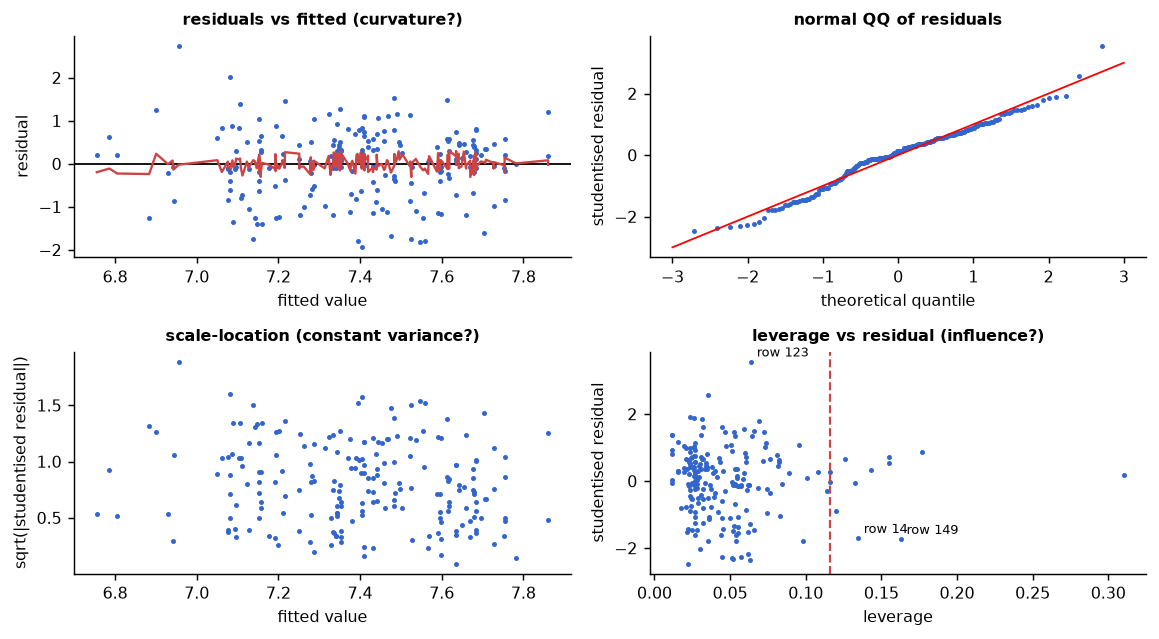

In [6]:
# The four standard diagnostic plots, computed from the fitted object.
infl = hansch.get_influence()
stud = infl.resid_studentized_internal
lev = infl.hat_matrix_diag
cook = infl.cooks_distance[0]
fitted = hansch.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(9.0, 5.0))
axes[0, 0].plot(fitted, hansch.resid, ".", ms=3.5, color="#36c")
axes[0, 0].axhline(0, color="k", lw=1)
lo = np.argsort(fitted)
axes[0, 0].plot(fitted[lo], pd.Series(hansch.resid).rolling(25, center=True, min_periods=5).mean().to_numpy()[lo],
                "-", color="#c44", lw=1.3)
axes[0, 0].set_xlabel("fitted value"); axes[0, 0].set_ylabel("residual")
axes[0, 0].set_title("residuals vs fitted (curvature?)", fontsize=9)
osm, osr = stats.probplot(stud, dist="norm", fit=False)
axes[0, 1].plot(osm, osr, ".", ms=3.5, color="#36c")
axes[0, 1].plot([-3, 3], [-3, 3], "r-", lw=1)
axes[0, 1].set_xlabel("theoretical quantile"); axes[0, 1].set_ylabel("studentised residual")
axes[0, 1].set_title("normal QQ of residuals", fontsize=9)
axes[1, 0].plot(fitted, np.sqrt(np.abs(stud)), ".", ms=3.5, color="#36c")
axes[1, 0].set_xlabel("fitted value"); axes[1, 0].set_ylabel("sqrt(|studentised residual|)")
axes[1, 0].set_title("scale-location (constant variance?)", fontsize=9)
axes[1, 1].plot(lev, stud, ".", ms=3.5, color="#36c")
axes[1, 1].axvline(2 * (len(DESC) + 1) / len(series), color="#c44", ls="--", lw=1.2)
big_cook = np.argsort(cook)[-3:]
for i in big_cook:
    axes[1, 1].annotate("row %d" % i, (lev[i], stud[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1, 1].set_xlabel("leverage"); axes[1, 1].set_ylabel("studentised residual")
axes[1, 1].set_title("leverage vs residual (influence?)", fontsize=9)
fig.tight_layout()
print("average leverage (p+1)/n = %.4f ; rule-of-thumb flag at 2x = %.4f ; max observed = %.4f"
      % ((len(DESC) + 1) / len(series), 2 * (len(DESC) + 1) / len(series), lev.max()))
print("compounds above the leverage flag: %d" % int((lev > 2 * (len(DESC) + 1) / len(series)).sum()))
print("largest Cook's distances: %s  (flag at 4/n = %.3f)"
      % (np.round(np.sort(cook)[-3:], 3), 4 / len(series)))
from statsmodels.stats.diagnostic import het_breuschpagan
print("Breusch-Pagan heteroscedasticity test p = %.3f" % het_breuschpagan(hansch.resid, Xs)[1])

<p class="caption"><b>Figure 2.</b> The four diagnostics of the Hansch model. Top left: residuals against fitted values with a running mean in red — flat, so there is no gross curvature to fix with a transformation. Top right: the studentised residuals follow the normal line in the middle and depart mildly in both tails, which is typical of potency data. Bottom left: the scale–location plot shows no obvious funnel, although the Breusch–Pagan test is borderline (p ≈ 0.03), so the standard errors in the table are mildly optimistic. Bottom right: leverage against residual, with the 2(p+1)/n flag as a dashed line; ten compounds exceed it and the three largest Cook's distances are labelled. Those three are several times the conventional 4/n alarm, so the fit — weak as it is — leans on a handful of unusual molecules, and any interpretation would have to be checked with and without them.</p>

The four plots answer four different questions, and only together do they constitute a check:

- **Residuals vs fitted** detects a wrong functional form — a U shape means a squared term or a log transform is missing.
- **QQ of residuals** checks the normality used by the small-sample inference. Heavy tails suggest robust regression or a bootstrap interval.
- **Scale–location** detects heteroscedasticity, which makes standard errors wrong (usually too small) without biasing the coefficients.
- **Leverage vs residual** finds influential points. **Leverage** measures how unusual a compound's *descriptors* are, independently of its potency; **Cook's distance**<sup class="c"><a href="#r6">[6]</a></sup> combines leverage with residual size to measure how much the fitted model would move if that compound were deleted.

<div class="box warn"><h4>High leverage is not a reason to delete a compound</h4>
<p>A high-leverage compound is an unusual molecule; it may be the most informative one in the series. Delete a point only for a documented reason (a curation error, a different assay, an off-scaffold structure), report that you did, and show the fit with and without it. Deleting points because they spoil the fit is p-hacking with extra steps (Unit 8, §7).</p></div>

## 5. Multicollinearity and the variance inflation factor

When predictors are correlated, $X^{\mathsf T}X$ is close to singular and $(X^{\mathsf T}X)^{-1}$ has large entries: the coefficients become unstable and their standard errors explode, even though the model's *predictions* may be perfectly good. The diagnostic is the **variance inflation factor**, $\mathrm{VIF}_j = 1/(1-R_j^2)$, where $R_j^2$ is the R² of regressing descriptor $j$ on all the others. A VIF of 10 means the standard error of that coefficient is √10 ≈ 3.2 times larger than it would be with uncorrelated descriptors<sup class="c"><a href="#r7">[7]</a></sup><sup class="c"><a href="#r8">[8]</a></sup>.

descriptors that are CONSTANT inside this series (zero information): ['AromaticRings', 'RingCount']
-> keeping 9 descriptors

HeavyAtoms      3448.8
MolWt           2413.5
TPSA             302.8
MolLogP          189.4
HBA              175.6
RotB             174.3
QED              136.2
HBD               66.1
FractionCSP3      63.6

largest absolute off-diagonal correlation: 0.911


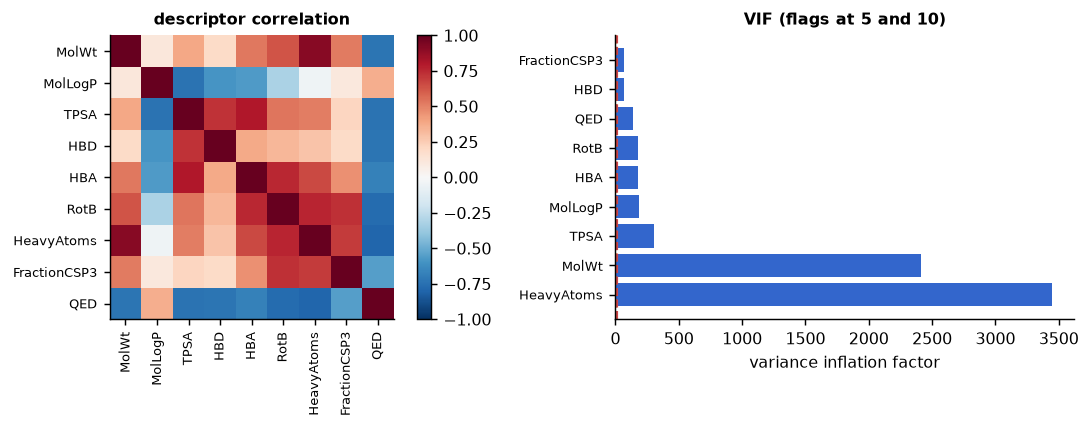

In [7]:
# VIFs, the descriptor correlation matrix, and a descriptor that is constant inside the series.
from statsmodels.stats.outliers_influence import variance_inflation_factor
const_cols = [c for c in DESC if series[c].nunique() == 1]
usable = [c for c in DESC if c not in const_cols]
print("descriptors that are CONSTANT inside this series (zero information):", const_cols)
print("-> keeping %d descriptors\n" % len(usable))
Xv = series[usable].to_numpy(float)
vifs = pd.Series({c: variance_inflation_factor(Xv, i) for i, c in enumerate(usable)}).sort_values(ascending=False)
corr = series[usable].corr()
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
im = axes[0].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set_xticks(range(len(usable))); axes[0].set_xticklabels(usable, rotation=90, fontsize=7)
axes[0].set_yticks(range(len(usable))); axes[0].set_yticklabels(usable, fontsize=7)
axes[0].set_title("descriptor correlation", fontsize=9)
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].barh(range(len(vifs)), vifs.to_numpy(), color="#36c")
axes[1].axvline(5, color="#e80", ls="--", lw=1.2); axes[1].axvline(10, color="#c44", ls="--", lw=1.2)
axes[1].set_yticks(range(len(vifs))); axes[1].set_yticklabels(vifs.index, fontsize=7)
axes[1].set_xlabel("variance inflation factor"); axes[1].set_title("VIF (flags at 5 and 10)", fontsize=9)
fig.tight_layout()
print(vifs.round(1).to_string())
print("\nlargest absolute off-diagonal correlation: %.3f"
      % corr.where(~np.eye(len(usable), dtype=bool)).abs().max().max())

<p class="caption"><b>Figure 3.</b> Left: the descriptor correlation matrix inside the series, showing the expected blocks — molecular weight, heavy-atom count and the surface-area terms move together, as do the hydrogen-bonding counts. Right: variance inflation factors, with the conventional flags at 5 and 10. Several descriptors sit far above 10: heavy-atom count and molecular weight reach VIFs in the thousands, because within this series they are almost the same quantity (their correlation is above 0.9), and QED exceeds 100 because it is by construction a function of the other descriptors — a desirability score computed from molecular weight, log P, TPSA, donors, acceptors and rotatable bonds. None of those coefficients may be interpreted individually.</p>

Note the line printed before the figure: two of the eleven descriptors — the ring counts — are **constant within this series**. That is not a bug, it is the definition of a congeneric series: every member has the same ring system. A constant column carries no information, is perfectly collinear with the intercept, and makes the design matrix singular; statsmodels absorbs it silently and reports a coefficient anyway, which is why they must be removed by hand. Checking `nunique()` on every predictor before fitting is a thirty-second habit that prevents an uninterpretable table.

The experiment that makes collinearity tangible is to drop one descriptor and watch the others move.

In [8]:
# Refit after dropping the most collinear descriptor, and compare every coefficient.
worst = vifs.index[0]
keep_cols = [c for c in usable if c != worst]
f_all = sm.OLS(y, sm.add_constant(series[usable])).fit()
f_drop = sm.OLS(y, sm.add_constant(series[keep_cols])).fit()
cmp_coef = pd.DataFrame({
    "with %s" % worst: f_all.params.reindex(["const"] + usable),
    "without %s" % worst: f_drop.params.reindex(["const"] + usable),
    "SE with": f_all.bse.reindex(["const"] + usable),
    "SE without": f_drop.bse.reindex(["const"] + usable)})
cmp_coef["change in coef"] = cmp_coef.iloc[:, 1] - cmp_coef.iloc[:, 0]
print("dropped descriptor: %s (VIF %.1f)" % (worst, vifs.iloc[0]))
print("R2 with %.4f -> without %.4f   (the fit barely changes)" % (f_all.rsquared, f_drop.rsquared))
print("largest absolute coefficient change: %.3f on %s"
      % (cmp_coef["change in coef"].abs().max(), cmp_coef["change in coef"].abs().idxmax()))
print("mean reduction in standard error: %.1f %%"
      % (100 * (1 - (cmp_coef["SE without"] / cmp_coef["SE with"]).dropna().mean())))
cmp_coef.round(4)

dropped descriptor: HeavyAtoms (VIF 3448.8)
R2 with 0.0785 -> without 0.0757   (the fit barely changes)
largest absolute coefficient change: 1.176 on FractionCSP3
mean reduction in standard error: 6.6 %


,with HeavyAtoms,without HeavyAtoms,SE with,SE without,change in coef
const,2.8410,1.6822,5.7497,5.5463,-1.1588
MolWt,0.0047,0.0004,0.0079,0.0055,-0.0043
MolLogP,0.1075,0.1397,0.2301,0.2261,0.0323
TPSA,-0.0148,-0.0169,0.0121,0.0118,-0.0020
HBD,0.5532,0.5982,0.3376,0.3322,0.0450
HBA,0.3560,0.3629,0.2019,0.2015,0.0069
RotB,0.2663,0.2779,0.1600,0.1591,0.0117
HeavyAtoms,-0.0991,NaN,0.1278,NaN,NaN
FractionCSP3,-5.0593,-6.2348,2.5945,2.1028,-1.1756
QED,4.4764,4.7384,3.9140,3.8954,0.2620


Removing one descriptor leaves the model's fit essentially unchanged — R² moves in the third decimal — while individual coefficients shift substantially and their standard errors shrink. That is the entire phenomenon: with collinear predictors the *sum* of their contributions is well determined and the *split* between them is not. A coefficient that changes sign when a correlated descriptor is removed should never be given a chemical interpretation.

Three responses to multicollinearity, in order of preference: (1) drop or merge redundant descriptors on chemical grounds; (2) accept it, if prediction rather than interpretation is the goal — collinearity does not hurt predictions; (3) regularise (§9), which trades a little bias for a large reduction in coefficient variance.

## 6. Categorical predictors, interactions, and ANOVA as a linear model

A categorical predictor with k levels enters the model as k − 1 indicator ("dummy") columns, so its coefficients are differences from a reference level. An **interaction** term $x_1 \cdot x_2$ lets the slope on one predictor depend on the value of another. And a one-way ANOVA is nothing but a linear model whose only predictor is a categorical variable: the F test of the ANOVA is the F test of that model<sup class="c"><a href="#r9">[9]</a></sup>.

In [9]:
# ANOVA as a linear model, and an interaction, on the five largest series.
top5 = counts.index[:5]
sub = exact.loc[exact.scaffold_smiles.isin(top5)].copy()
sub["series"] = pd.Categorical(["S%d" % (list(top5).index(s) + 1) for s in sub["scaffold_smiles"]])
lm_cat = smf.ols("pActivity ~ C(series)", data=sub).fit()
anova = sm.stats.anova_lm(lm_cat, typ=2)
f_direct = stats.f_oneway(*[g["pActivity"].to_numpy() for _, g in sub.groupby("series", observed=True)])
print("linear model with a categorical predictor:")
print(lm_cat.summary2().tables[1].round(4).to_string())
print("\nANOVA table from the same model:\n", anova.round(4).to_string())
print("\nscipy.stats.f_oneway on the same data: F = %.4f, p = %.3g  <- identical"
      % (f_direct.statistic, f_direct.pvalue))

lm_int = smf.ols("pActivity ~ MolLogP * C(series)", data=sub).fit()
lm_add = smf.ols("pActivity ~ MolLogP + C(series)", data=sub).fit()
lr_stat = 2 * (lm_int.llf - lm_add.llf)
lr_p = stats.chi2.sf(lr_stat, lm_int.df_model - lm_add.df_model)
print("\nadditive model   : R2 %.3f, AIC %.1f" % (lm_add.rsquared, lm_add.aic))
print("interaction model: R2 %.3f, AIC %.1f" % (lm_int.rsquared, lm_int.aic))
print("likelihood-ratio test for the interaction: chi2 = %.2f on %d df, p = %.4f"
      % (lr_stat, int(lm_int.df_model - lm_add.df_model), lr_p))

linear model with a categorical predictor:
                  Coef.  Std.Err.         t   P>|t|  [0.025  0.975]
Intercept        7.3967    0.0571  129.5612  0.0000  7.2844  7.5090
C(series)[T.S2] -1.3273    0.1212  -10.9496  0.0000 -1.5657 -1.0890
C(series)[T.S3] -0.4184    0.1377   -3.0396  0.0025 -0.6891 -0.1477
C(series)[T.S4] -0.5646    0.1450   -3.8948  0.0001 -0.8496 -0.2796
C(series)[T.S5] -0.0586    0.1540   -0.3807  0.7037 -0.3613  0.2441

ANOVA table from the same model:
              sum_sq     df        F  PR(>F)
C(series)   85.9997    4.0  31.8669     0.0
Residual   253.0043  375.0      NaN     NaN

scipy.stats.f_oneway on the same data: F = 31.8669, p = 7.23e-23  <- identical

additive model   : R2 0.266, AIC 929.7
interaction model: R2 0.268, AIC 936.7
likelihood-ratio test for the interaction: chi2 = 1.01 on 4 df, p = 0.9082


The F statistic from `anova_lm` on the linear model and the one from `scipy.stats.f_oneway` are the same number to every printed decimal, because they are the same test. Seeing this once removes the idea that ANOVA and regression are different techniques: ANOVA is the special case in which all predictors are categorical, and the familiar "sum of squares between groups over sum of squares within groups" is the model's explained variance over its residual variance.

The interaction model asks whether the slope on lipophilicity differs between series. The likelihood-ratio test compares the two nested models: twice the difference in log-likelihood is compared with a chi-square distribution on the difference in parameters. Here the test does not support the extra complexity at the conventional level, and AIC agrees — the simpler additive model is preferred.

pooled slope (additive model)  : -0.179
per-series slopes from the interaction model:
  S1 (reference): -0.150
  S2: -0.267  (difference from S1: -0.117, p = 0.598)
  S3: -0.310  (difference from S1: -0.161, p = 0.509)
  S4: +0.017  (difference from S1: +0.167, p = 0.632)
  S5: -0.203  (difference from S1: -0.053, p = 0.831)


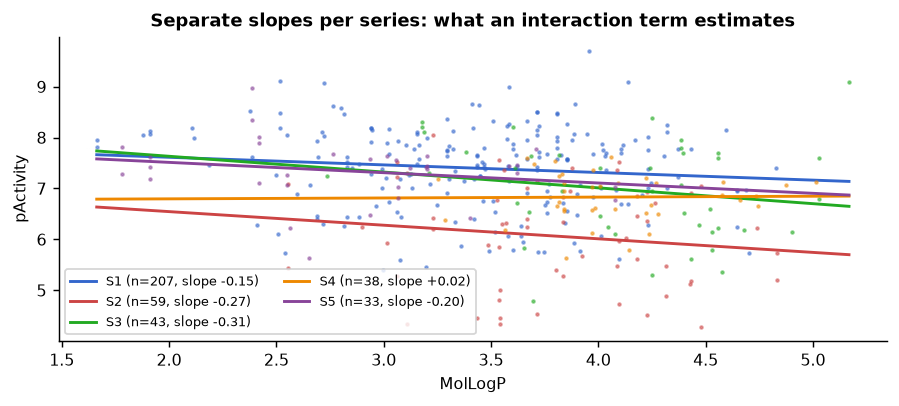

In [10]:
# What the interaction means, drawn.
fig, ax = plt.subplots(figsize=(7.0, 3.2))
colors = ["#36c", "#c44", "#2a2", "#e80", "#849"]
xs = np.linspace(sub.MolLogP.min(), sub.MolLogP.max(), 50)
for i, (name, g) in enumerate(sub.groupby("series", observed=True)):
    ax.plot(g.MolLogP, g.pActivity, ".", ms=3, alpha=0.5, color=colors[i])
    b, a = np.polyfit(g.MolLogP, g.pActivity, 1)
    ax.plot(xs, a + b * xs, "-", color=colors[i], lw=1.6,
            label="%s (n=%d, slope %+.2f)" % (name, len(g), b))
ax.set_xlabel("MolLogP"); ax.set_ylabel("pActivity")
ax.set_title("Separate slopes per series: what an interaction term estimates")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
print("pooled slope (additive model)  : %+.3f" % lm_add.params["MolLogP"])
print("per-series slopes from the interaction model:")
print("  S1 (reference): %+.3f" % lm_int.params["MolLogP"])
for lev in ["S2", "S3", "S4", "S5"]:
    keys = [k for k in lm_int.params.index if ":" in k and lev in k]
    for key in keys:
        print("  %s: %+.3f  (difference from S1: %+.3f, p = %.3f)"
              % (lev, lm_int.params["MolLogP"] + lm_int.params[key], lm_int.params[key], lm_int.pvalues[key]))

<p class="caption"><b>Figure 4.</b> Potency against lipophilicity within each of the five series, with a separate least-squares line per series. The lines have visibly different slopes and intercepts, which is what an interaction term formalises; but the scatter around each line is large and the per-series sample sizes are small, so the likelihood-ratio test above cannot distinguish these slopes from a single common one. The figure is the right way to decide whether an interaction is worth testing — look first, then test, and say in the paper that you looked.</p>

### 6.1 Transformations and the parabolic Hansch model

Hansch's own models were rarely linear in log P: potency usually rises with lipophilicity, peaks, and falls again as the compound becomes too greasy to stay in solution or too promiscuous to be selective. He captured that with a **quadratic term**, and the resulting parabolic model is the most-cited functional form in classical QSAR. Adding a squared term keeps the model linear in its coefficients, so nothing about the estimation changes — only the design matrix.

linear    : R2 = 0.0006, AIC = 8414.6
parabolic : R2 = 0.0205, AIC = 8361.3, quadratic coefficient -0.0791 (p = 0.0000)
likelihood-ratio test for the quadratic term: chi2 = 55.38 on 1 df, p = 0.0000
implied optimum log P = 3.30  (data range -1.3 to 7.5)


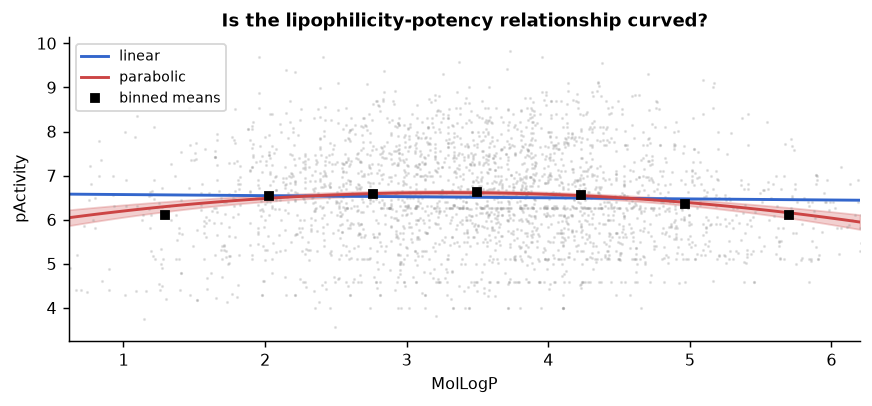

In [11]:
# A linear and a parabolic model in lipophilicity, on the full exact subset.
lin = smf.ols("pActivity ~ MolLogP", data=exact).fit()
quad = smf.ols("pActivity ~ MolLogP + I(MolLogP**2)", data=exact).fit()
lr = 2 * (quad.llf - lin.llf); lr_p = stats.chi2.sf(lr, 1)
xs = np.linspace(exact.MolLogP.quantile(0.01), exact.MolLogP.quantile(0.99), 100)
pred_q = quad.get_prediction(pd.DataFrame({"MolLogP": xs})).summary_frame(alpha=0.05)
fig, ax = plt.subplots(figsize=(6.8, 3.2))
ax.plot(exact.MolLogP, exact.pActivity, ".", ms=1.5, alpha=0.25, color="#999")
ax.plot(xs, lin.params["Intercept"] + lin.params["MolLogP"] * xs, "-", color="#36c", lw=1.6, label="linear")
ax.plot(xs, pred_q["mean"], "-", color="#c44", lw=1.6, label="parabolic")
ax.fill_between(xs, pred_q["mean_ci_lower"], pred_q["mean_ci_upper"], color="#c44", alpha=0.25)
binned = exact.groupby(pd.cut(exact.MolLogP, 12), observed=True)["pActivity"].mean()
ax.plot([iv.mid for iv in binned.index], binned.to_numpy(), "ks", ms=4, label="binned means")
ax.set_xlabel("MolLogP"); ax.set_ylabel("pActivity"); ax.set_xlim(xs[0], xs[-1])
ax.set_title("Is the lipophilicity-potency relationship curved?"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("linear    : R2 = %.4f, AIC = %.1f" % (lin.rsquared, lin.aic))
print("parabolic : R2 = %.4f, AIC = %.1f, quadratic coefficient %+.4f (p = %.4f)"
      % (quad.rsquared, quad.aic, quad.params["I(MolLogP ** 2)"], quad.pvalues["I(MolLogP ** 2)"]))
print("likelihood-ratio test for the quadratic term: chi2 = %.2f on 1 df, p = %.4f" % (lr, lr_p))
opt = -quad.params["MolLogP"] / (2 * quad.params["I(MolLogP ** 2)"])
print("implied optimum log P = %.2f  (data range %.1f to %.1f)" % (opt, exact.MolLogP.min(), exact.MolLogP.max()))

<p class="caption"><b>Figure 5.</b> Potency against calculated lipophilicity for all 2,764 compounds, with the linear fit (blue), the parabolic fit with its confidence band (red) and twelve binned means (black squares) that show the shape of the data independently of either model. The quadratic term is strongly supported — the likelihood-ratio test gives chi-square above 50 on 1 degree of freedom — and the fitted parabola peaks near log P 3.3, which is a chemically plausible place for an optimum. And yet the parabolic model explains about 2 % of the variance against the linear model's 0.06 %: the curvature is real but tiny. An "optimum log P" quoted from a model with R² of 0.02 is a number a referee will not accept, and reporting the R² next to it is what keeps the claim honest.</p>

## 7. Chance correlation: the Topliss–Costello experiment

In 1972 Topliss and Costello showed by simulation that if you search enough descriptors on few enough compounds, an impressive correlation appears from random numbers<sup class="c"><a href="#r4">[4]</a></sup>. The expected R² of a regression of pure noise on p predictors with n observations is approximately p/(n−1) — with 11 descriptors and 33 compounds, that is about 0.34 *before any real signal exists*.

Our fifth series has 33 compounds. Fitting the same eleven descriptors to it gives a respectable-looking R². The experiment that decides whether to believe it is **response randomisation** (y-scrambling): permute the potencies, refit, repeat, and look at where the real R² falls in the resulting null distribution.

series size n = 33, descriptors p = 11 -> 3.0 compounds per descriptor
fit on the real data : R2 = 0.595, adjusted R2 = 0.436, F p-value = 0.0050
null from scrambling : mean R2 = 0.278, 95th percentile = 0.484, maximum = 0.658
expected under noise, p/(n-1) = 0.344
fraction of scrambles reaching the real R2: 0.0050


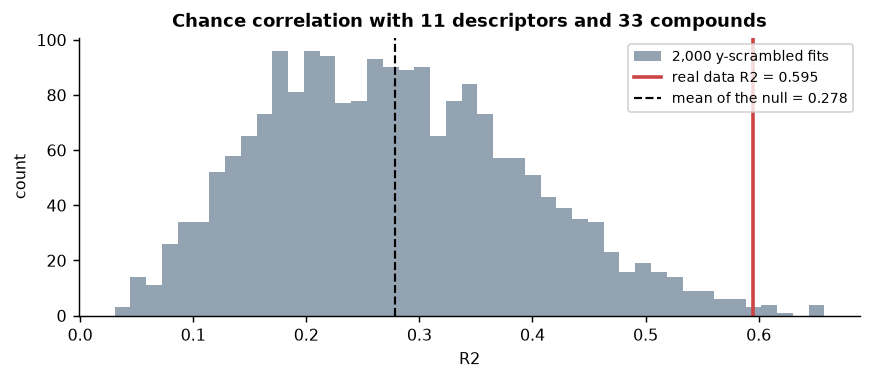

In [12]:
# A 'good' QSAR on 33 compounds, and the chance-correlation null that evaluates it.
small = exact.loc[exact.scaffold_smiles == counts.index[4]].reset_index(drop=True)
Xsm = sm.add_constant(small[DESC].to_numpy(float))
ysm = small["pActivity"].to_numpy()
fit_small = sm.OLS(ysm, Xsm).fit()
scram = np.array([sm.OLS(np.random.default_rng(i).permutation(ysm), Xsm).fit().rsquared for i in range(2000)])
p_scram = float(np.mean(scram >= fit_small.rsquared))
fig, ax = plt.subplots(figsize=(6.8, 3.0))
ax.hist(scram, bins=45, color="#89a", alpha=0.9, label="2,000 y-scrambled fits")
ax.axvline(fit_small.rsquared, color="#c44", lw=2, label="real data R2 = %.3f" % fit_small.rsquared)
ax.axvline(scram.mean(), color="k", ls="--", lw=1.2, label="mean of the null = %.3f" % scram.mean())
ax.set_xlabel("R2"); ax.set_ylabel("count"); ax.legend(fontsize=7.5)
ax.set_title("Chance correlation with 11 descriptors and 33 compounds")
fig.tight_layout()
print("series size n = %d, descriptors p = %d -> %.1f compounds per descriptor"
      % (len(small), len(DESC), len(small) / len(DESC)))
print("fit on the real data : R2 = %.3f, adjusted R2 = %.3f, F p-value = %.4f"
      % (fit_small.rsquared, fit_small.rsquared_adj, fit_small.f_pvalue))
print("null from scrambling : mean R2 = %.3f, 95th percentile = %.3f, maximum = %.3f"
      % (scram.mean(), np.percentile(scram, 95), scram.max()))
print("expected under noise, p/(n-1) = %.3f" % (len(DESC) / (len(small) - 1)))
print("fraction of scrambles reaching the real R2: %.4f" % p_scram)

<p class="caption"><b>Figure 6.</b> The chance-correlation experiment. Scrambling the potencies 2,000 times and refitting the same eleven descriptors on the same 33 compounds produces R² values averaging about 0.28 — of the order of the theoretical p/(n−1) ≈ 0.34 — with a 95th percentile near 0.48 and a maximum near 0.66. The real fit, R² ≈ 0.60, is beyond the 95th percentile (about one scramble in two hundred does better) but is manifestly <em>not</em> the "R² = 0.6, excellent model" of a naive report: more than a quarter of that R² would have appeared from random numbers.</p>

Two numbers in that output are the antidote to the naive report. The **adjusted R²**, which penalises the number of predictors,

$$R^2_{\text{adj}} = 1 - (1-R^2)\frac{n-1}{n-p-1},$$

falls from about 0.60 to about 0.44 — the honest figure. And the empirical scrambling p-value of about 0.005 is the one to quote. Every QSAR paper from this laboratory reports a y-randomisation control for exactly this reason<sup class="c"><a href="#r10">[10]</a></sup><sup class="c"><a href="#r11">[11]</a></sup><sup class="c"><a href="#r12">[12]</a></sup>, and Unit 12 repeats the experiment for machine-learning models, where the number of effective parameters is much larger and the danger correspondingly worse<sup class="c"><a href="#r13">[13]</a></sup>.

## 8. Logistic regression

When the response is binary — active or inactive, responder or non-responder — the linear model is applied to the **log-odds** instead of to the response:

$$\log\frac{\Pr(y=1\mid x)}{1-\Pr(y=1\mid x)} = \beta_0 + \beta_1x_1 + \dots + \beta_px_p .$$

The coefficients are fitted by maximising the Bernoulli likelihood rather than by least squares, and each $e^{\beta_j}$ is an **odds ratio**: the multiplicative change in the odds of being active for a one-unit increase in $x_j$, holding the others fixed. With standardised predictors, "one unit" is one standard deviation, which makes the coefficients comparable.

We classify ROCK1 compounds as active at **pActivity ≥ 6.5** (IC50 ≤ about 316 nM), the threshold the course uses throughout, and model the probability of activity from the eleven descriptors.

n = 2764 | actives 1339 (48.4 %) | McFadden pseudo-R2 = 0.087 | LLR p = 2.02e-64
events per variable (EPV) = 122  (classical minimum 10)
                coef  odds_ratio  or_low  or_high      p
HBA           -0.321       0.725   0.628    0.837  0.000
MolLogP       -0.201       0.818   0.690    0.971  0.022
HeavyAtoms    -0.183       0.833   0.494    1.402  0.491
TPSA          -0.167       0.847   0.667    1.074  0.171
AromaticRings -0.164       0.849   0.682    1.056  0.141
FractionCSP3   0.103       1.108   0.969    1.268  0.134
RingCount      0.209       1.232   0.970    1.565  0.088
MolWt          0.257       1.293   0.815    2.051  0.275
HBD            0.310       1.364   1.195    1.557  0.000
QED            0.456       1.578   1.282    1.943  0.000
RotB           0.816       2.261   1.898    2.695  0.000


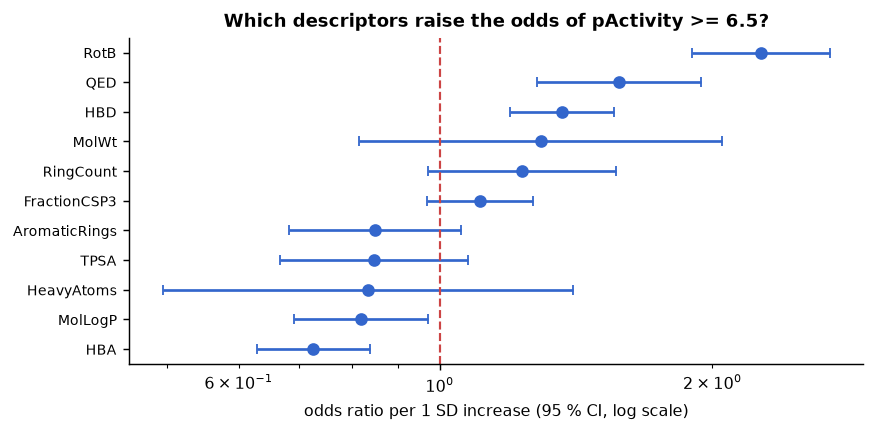

In [13]:
# Logistic regression on the full exact subset, with standardised descriptors.
y_cls = (exact["pActivity"] >= 6.5).astype(int).to_numpy()
Z = (exact[DESC] - exact[DESC].mean()) / exact[DESC].std()
logit = sm.Logit(y_cls, sm.add_constant(Z)).fit(disp=0)
odds = pd.DataFrame({"coef": logit.params, "odds_ratio": np.exp(logit.params),
                     "or_low": np.exp(logit.conf_int()[0]), "or_high": np.exp(logit.conf_int()[1]),
                     "p": logit.pvalues}).drop(index="const").sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.errorbar(odds["odds_ratio"], range(len(odds)),
            xerr=[odds["odds_ratio"] - odds["or_low"], odds["or_high"] - odds["odds_ratio"]],
            fmt="o", color="#36c", capsize=3)
ax.axvline(1, color="#c44", ls="--", lw=1.2)
ax.set_yticks(range(len(odds))); ax.set_yticklabels(odds.index, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("odds ratio per 1 SD increase (95 % CI, log scale)")
ax.set_title("Which descriptors raise the odds of pActivity >= 6.5?")
fig.tight_layout()
print("n = %d | actives %d (%.1f %%) | McFadden pseudo-R2 = %.3f | LLR p = %.3g"
      % (len(y_cls), y_cls.sum(), 100 * y_cls.mean(), logit.prsquared, logit.llr_pvalue))
print("events per variable (EPV) = %.0f  (classical minimum 10)" % (min(y_cls.sum(), (1 - y_cls).sum()) / len(DESC)))
print(odds.round(3).to_string())

<p class="caption"><b>Figure 7.</b> Odds ratios per one-standard-deviation increase in each descriptor, with 95 % intervals, on a logarithmic axis. The number of rotatable bonds has the largest effect — about 2.3 times the odds of being active per standard deviation — followed by QED and the hydrogen-bond donor count; the acceptor count and lipophilicity push the other way. Intervals that cross the dashed line at 1 belong to descriptors with no detectable association. The McFadden pseudo-R² of about 0.09 says what the forest plot cannot: taken together these descriptors explain very little, and the model is nowhere near a usable classifier.</p>

The **events-per-variable** figure printed above the table is the classical sample-size rule for logistic regression: at least ten events (members of the rarer class) per estimated coefficient, relaxed in later work but still a useful floor<sup class="c"><a href="#r14">[14]</a></sup><sup class="c"><a href="#r15">[15]</a></sup>. Here we have well over a hundred, which is why the intervals are narrow.

### 8.1 Separation

If some combination of predictors perfectly predicts the outcome, the likelihood has no maximum: the coefficient runs to infinity and the algorithm either fails or returns an enormous estimate with an enormous standard error<sup class="c"><a href="#r16">[16]</a></sup>. This happens routinely in small datasets with a strong predictor, and the output is easy to misread as a wonderful result.

In [14]:
# Complete separation, and the two standard cures.
sub60 = exact.sample(60, random_state=0).reset_index(drop=True)
y60 = (sub60["pActivity"] >= 6.5).astype(int).to_numpy()
x_sep = y60 * 5.0 + np.random.default_rng(0).normal(0, 0.01, 60)    # a predictor that separates perfectly
X_sep = sm.add_constant(x_sep)
try:
    bad = sm.Logit(y60, X_sep).fit(disp=0)
    print("unregularised fit: coefficient %.1f, standard error %.1f" % (bad.params[1], bad.bse[1]))
except Exception as e:
    print("unregularised maximum likelihood FAILS:", type(e).__name__, "-", str(e)[:70])
pen = sm.Logit(y60, X_sep).fit_regularized(alpha=1.0, disp=0)        # L2-penalised likelihood
print("L2-penalised fit : coefficient %.3f  (finite, shrunken)" % pen.params[1])
from sklearn.linear_model import LogisticRegression
skl = LogisticRegression(C=1.0, max_iter=1000).fit(x_sep.reshape(-1, 1), y60)
print("sklearn (L2 by default, C=1): coefficient %.3f" % skl.coef_[0, 0])
print("\nseparation check: are the two classes disjoint on this predictor?",
      x_sep[y60 == 1].min() > x_sep[y60 == 0].max())
print("for comparison, a real descriptor (MolLogP) on the same 60 compounds:")
real = sm.Logit(y60, sm.add_constant(sub60["MolLogP"].to_numpy())).fit(disp=0)
print("  coefficient %.3f, SE %.3f, p = %.3f" % (real.params[1], real.bse[1], real.pvalues[1]))

/usr/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/usr/lib/python3.11/site-packages/statsmodels/discrete/discr

Statsmodels issues an explicit <code>PerfectSeparationWarning</code> and then fails with a singular-matrix error, which is the best possible behaviour; the penalised fits return finite, shrunken coefficients around 1.6–1.8, and a genuine descriptor on the same 60 compounds gives a small, non-significant coefficient for comparison. Both Firth's bias-reduced likelihood<sup class="c"><a href="#r17">[17]</a></sup> and a simple L2 penalty are accepted remedies, and scikit-learn's `LogisticRegression` applies an L2 penalty **by default**, which is why it never warns you about separation — a convenience that hides a diagnostic. If a coefficient in your logistic model exceeds about 10 in magnitude, check for separation before interpreting it.

### 8.2 Calibration

A classifier can rank perfectly and still produce meaningless probabilities. **Calibration** asks whether, among the compounds the model gives a 70 % probability of being active, about 70 % really are. It is assessed by binning the predicted probabilities and plotting the observed frequency against the mean prediction in each bin<sup class="c"><a href="#r18">[18]</a></sup>.

logistic model : AUC 0.705, Brier 0.220
distorted      : AUC 0.705, Brier 0.243  <- identical ranking, worse probabilities
base rate of actives: 0.484 | mean predicted probability: 0.484


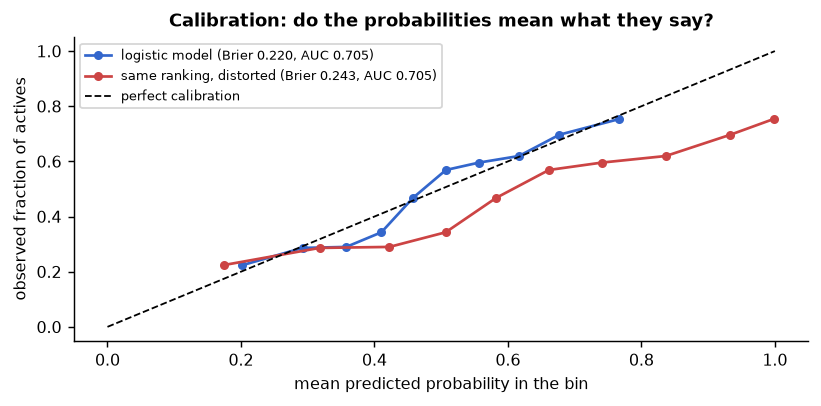

In [15]:
# Calibration curve of the logistic model, with a deliberately miscalibrated comparison.
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss
p_hat = logit.predict(sm.add_constant(Z))
p_bad = np.clip(p_hat * 1.6 - 0.15, 0.001, 0.999)        # the same ranking, distorted probabilities
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for ph, name, c in [(p_hat, "logistic model", "#36c"), (p_bad, "same ranking, distorted", "#c44")]:
    frac, mean_pred = calibration_curve(y_cls, ph, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", ms=4, color=c,
            label="%s (Brier %.3f, AUC %.3f)" % (name, brier_score_loss(y_cls, ph), roc_auc_score(y_cls, ph)))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.set_xlabel("mean predicted probability in the bin"); ax.set_ylabel("observed fraction of actives")
ax.set_title("Calibration: do the probabilities mean what they say?"); ax.legend(fontsize=7)
fig.tight_layout()
print("logistic model : AUC %.3f, Brier %.3f" % (roc_auc_score(y_cls, p_hat), brier_score_loss(y_cls, p_hat)))
print("distorted      : AUC %.3f, Brier %.3f  <- identical ranking, worse probabilities"
      % (roc_auc_score(y_cls, p_bad), brier_score_loss(y_cls, p_bad)))
print("base rate of actives: %.3f | mean predicted probability: %.3f" % (y_cls.mean(), p_hat.mean()))

<p class="caption"><b>Figure 8.</b> Calibration curves. The logistic model (blue) tracks the diagonal closely — unsurprisingly, since maximum-likelihood logistic regression fitted and evaluated on the same data is calibrated by construction. The red curve is the <em>same model's ranking</em> with the probabilities stretched; its ROC-AUC is identical to three decimals because AUC depends only on the ordering, while its Brier score is clearly worse and its curve departs from the diagonal at both ends. A model can therefore be a perfect ranker and a useless probability estimate, which matters whenever a predicted probability feeds a decision — a screening budget, a triage threshold, a cost calculation.</p>

Two cautions. Calibration measured on the training data is optimistic; the honest version uses held-out predictions, which Unit 12 builds. And a calibration curve says nothing about discrimination: a model that predicts the base rate for every compound is perfectly calibrated and completely useless.

## 9. Regularisation: ridge, lasso and elastic net

So far we used eleven hand-picked descriptors. Real descriptor sets are much larger, and with p approaching n ordinary least squares breaks down: the variance of $\hat\beta$ grows without bound as $X^{\mathsf T}X$ approaches singularity. Regularisation adds a penalty on the size of the coefficients, accepting a little bias in exchange for a large reduction in variance:

$$\text{ridge:}\ \min_\beta \lVert y-X\beta\rVert^2 + \lambda\lVert\beta\rVert_2^2,\qquad
\text{lasso:}\ \min_\beta \lVert y-X\beta\rVert^2 + \lambda\lVert\beta\rVert_1,$$

with the **elastic net** mixing the two. Ridge<sup class="c"><a href="#r19">[19]</a></sup> shrinks all coefficients smoothly towards zero and keeps every predictor; the lasso<sup class="c"><a href="#r20">[20]</a></sup> sets some exactly to zero, performing selection; the elastic net<sup class="c"><a href="#r21">[21]</a></sup> keeps groups of correlated predictors together instead of picking one arbitrarily. The geometry is the explanation: the L1 constraint region has corners on the axes, and a corner is where the solution tends to land.

We now compute the full RDKit descriptor set — about 200 usable numerical descriptors — for all 2,764 compounds and compare.

In [16]:
# Two hundred descriptors for 2,764 compounds (about 15 s), then OLS against the penalised fits.
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
RDLogger.DisableLog("rdApp.*")
mols = [Chem.MolFromSmiles(s) for s in exact["std_smiles"]]
D = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in mols]).replace([np.inf, -np.inf], np.nan)
good = [c for c in D.columns if D[c].notna().all() and D[c].std() > 0]
from sklearn.preprocessing import StandardScaler
Xbig = StandardScaler().fit_transform(D[good].to_numpy(float))
ybig = exact["pActivity"].to_numpy()
print("RDKit descriptors computed: %d | usable (finite, non-constant): %d | compounds: %d"
      % (D.shape[1], len(good), len(ybig)))

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV
from sklearn.model_selection import KFold, cross_val_score
kf = KFold(5, shuffle=True, random_state=0)
grid = np.logspace(-2.2, 0.3, 25)
lasso_cv = LassoCV(alphas=grid, cv=5, random_state=0, tol=1e-3, max_iter=5000).fit(Xbig, ybig)
enet_cv = ElasticNetCV(alphas=grid, l1_ratio=[0.2, 0.5, 0.8, 0.95], cv=5, random_state=0,
                       tol=1e-3, max_iter=5000).fit(Xbig, ybig)
ridge_cv = RidgeCV(alphas=np.logspace(-2, 4, 40)).fit(Xbig, ybig)
rows = []
for name, model in [("OLS (no penalty)", LinearRegression()),
                    ("Ridge", Ridge(alpha=ridge_cv.alpha_)),
                    ("Lasso", Lasso(alpha=lasso_cv.alpha_, tol=1e-3, max_iter=5000)),
                    ("Elastic net", ElasticNet(alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, tol=1e-3, max_iter=5000))]:
    sc = cross_val_score(model, Xbig, ybig, cv=kf, scoring="r2")
    m = model.fit(Xbig, ybig)
    rows.append({"model": name, "train R2": m.score(Xbig, ybig), "CV R2": sc.mean(), "CV sd": sc.std(),
                 "non-zero coefficients": int(np.sum(np.abs(m.coef_) > 1e-10))})
reg_tab = pd.DataFrame(rows).set_index("model")
print("\nchosen penalties: ridge alpha %.3f | lasso alpha %.4f | elastic net alpha %.4f, l1_ratio %.2f"
      % (ridge_cv.alpha_, lasso_cv.alpha_, enet_cv.alpha_, enet_cv.l1_ratio_))
reg_tab.round(3)

RDKit descriptors computed: 217 | usable (finite, non-constant): 200 | compounds: 2764

chosen penalties: ridge alpha 0.084 | lasso alpha 0.0063 | elastic net alpha 0.0063, l1_ratio 0.20


,train R2,CV R2,CV sd,non-zero coefficients
model,,,,
OLS (no penalty),0.440,-1.274,1.842,200
Ridge,0.434,0.125,0.375,200
Lasso,0.363,0.294,0.043,103
Elastic net,0.400,0.314,0.043,154


The table is the bias–variance trade-off in four rows. Ordinary least squares fits the training data best — it always does, it is the unbiased minimiser of training error — and its **cross-validated R² is negative**, meaning it predicts held-out compounds worse than the mean of the training set does. With 200 correlated descriptors and 2,764 compounds, the unpenalised solution is fitting noise. The penalised models recover: ridge reaches a cross-validated R² of about 0.13 with a large fold-to-fold spread, while the lasso reaches about 0.29 and the elastic net about 0.31, both with a fold-to-fold spread nearly ten times smaller than ridge's. The lasso does it with roughly half of the 200 descriptors set to exactly zero; the elastic net keeps more of them, which is what a mixed penalty does with correlated predictors.

Negative cross-validated R² is the single clearest symptom of over-fitting, and it is invisible to anyone who reports only the training R². This is also the first appearance in the course of the rule that governs all of Block D: **the penalty must be chosen inside the cross-validation, not on the test data**.

alpha = 0.5285 ->   0 non-zero coefficients
alpha = 0.1042 ->  14 non-zero coefficients
alpha = 0.0063 -> 103 non-zero coefficients
alpha = 0.0098 ->  90 non-zero coefficients
CV-optimal alpha = 0.0063, CV MSE = 0.8515 (+- 0.0539 across folds)


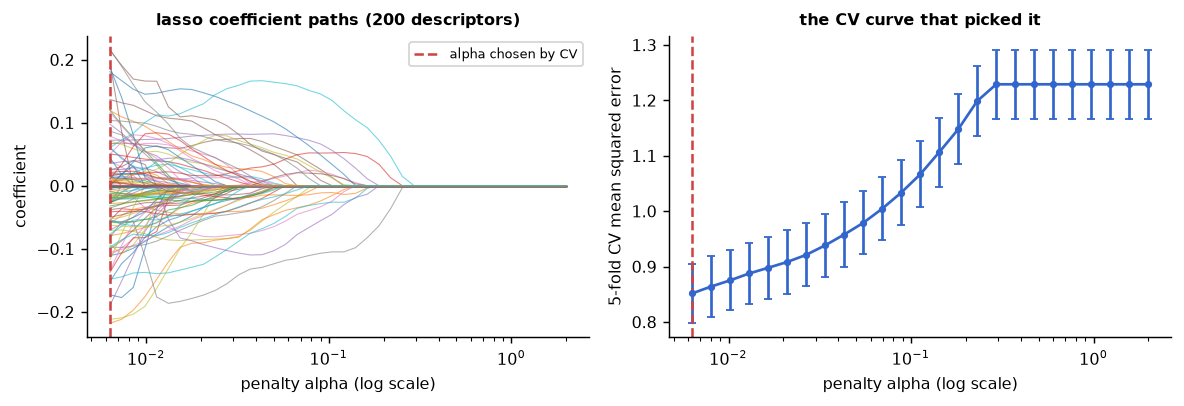

In [17]:
# The coefficient path and the cross-validation curve that chooses the penalty.
from sklearn.linear_model import lasso_path
alphas_path, coefs_path, _ = lasso_path(Xbig, ybig, alphas=np.logspace(-2.2, 0.3, 40))
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
for j in range(coefs_path.shape[0]):
    axes[0].plot(alphas_path, coefs_path[j], lw=0.6, alpha=0.6)
axes[0].axvline(lasso_cv.alpha_, color="#c44", ls="--", lw=1.4, label="alpha chosen by CV")
axes[0].set_xscale("log"); axes[0].set_xlabel("penalty alpha (log scale)"); axes[0].set_ylabel("coefficient")
axes[0].set_title("lasso coefficient paths (200 descriptors)", fontsize=9); axes[0].legend(fontsize=7)
mse = lasso_cv.mse_path_.mean(axis=1); sd = lasso_cv.mse_path_.std(axis=1)
axes[1].errorbar(lasso_cv.alphas_, mse, yerr=sd, fmt="o-", ms=3, color="#36c", capsize=2)
axes[1].axvline(lasso_cv.alpha_, color="#c44", ls="--", lw=1.4)
axes[1].set_xscale("log"); axes[1].set_xlabel("penalty alpha (log scale)")
axes[1].set_ylabel("5-fold CV mean squared error")
axes[1].set_title("the CV curve that picked it", fontsize=9)
fig.tight_layout()
n_nonzero = (np.abs(coefs_path) > 1e-10).sum(axis=0)
for a in (0.5, 0.1, lasso_cv.alpha_, 0.01):
    k = int(np.argmin(np.abs(alphas_path - a)))
    print("alpha = %.4f -> %3d non-zero coefficients" % (alphas_path[k], n_nonzero[k]))
print("CV-optimal alpha = %.4f, CV MSE = %.4f (+- %.4f across folds)"
      % (lasso_cv.alpha_, mse.min(), sd[int(np.argmin(mse))]))

<p class="caption"><b>Figure 9.</b> Left: each line is one descriptor's coefficient as the lasso penalty is relaxed from strong (right) to weak (left); at a strong penalty everything is zero and descriptors enter one by one as alpha decreases. Right: the five-fold cross-validation error against alpha, with the fold-to-fold standard deviation as error bars; it falls, flattens, and the minimum selects the penalty marked by the dashed line in both panels. Note how flat the curve is near its minimum — several alphas differing by a factor of three are statistically indistinguishable, which is the argument for the "one standard error" rule of choosing the largest penalty within one standard error of the best.</p>

### 9.1 Is the lasso's selection stable?

A lasso coefficient path tells you *which* descriptors were selected on *this* sample. It is tempting to read the selected set as the chemistry. The test of that reading is to resample the compounds and see whether the same descriptors keep being selected — the idea behind stability selection<sup class="c"><a href="#r22">[22]</a></sup>.

penalty fixed at alpha = 0.02 -> 62 non-zero coefficients on the full data
descriptors selected in >= 80 % of resamples : 33
descriptors selected in <= 20 % of resamples : 113

the ten most stable descriptors:
                     descriptor  selected_in  frequency  coef_full_data
                   BCUT2D_MWLOW           60   1.000000       -0.085199
                         AvgIpc           60   1.000000        0.094215
                   fr_piperzine           60   1.000000        0.078810
                   fr_thiophene           60   1.000000        0.054135
                    fr_priamide           60   1.000000       -0.046094
                    EState_VSA6           60   1.000000        0.068985
                    fr_pyridine           60   1.000000        0.148493
NumUnspecifiedAtomStereoCenters           60   1.000000        0.079737
                         fr_NH0           59   0.983333       -0.093667
                    EState_VSA5           59   0.983333       -0.05686

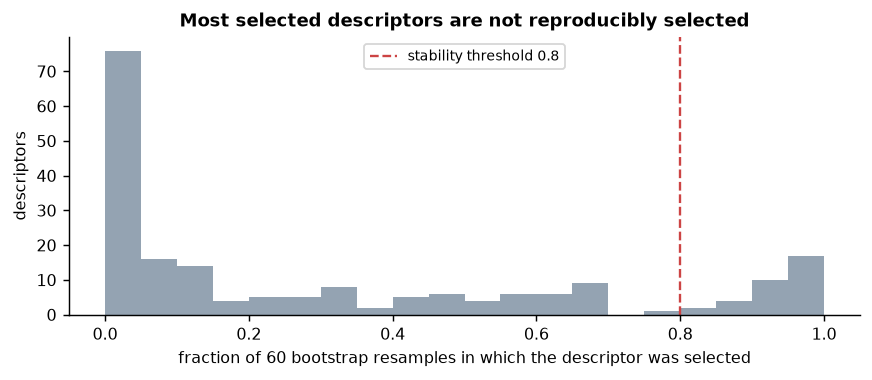

In [18]:
# Bootstrap stability of lasso selection: 60 resamples at a fixed penalty.
alpha_fix = 0.02
B = 60
sel_count = np.zeros(len(good))
for b in range(B):
    idx = np.random.default_rng(b).integers(0, len(ybig), len(ybig))
    lb = Lasso(alpha=alpha_fix, tol=1e-3, max_iter=5000).fit(Xbig[idx], ybig[idx])
    sel_count += (np.abs(lb.coef_) > 1e-10)
full = Lasso(alpha=alpha_fix, tol=1e-3, max_iter=5000).fit(Xbig, ybig)
freq = pd.DataFrame({"descriptor": good, "selected_in": sel_count.astype(int),
                     "frequency": sel_count / B, "coef_full_data": full.coef_}).sort_values("frequency",
                                                                                            ascending=False)
fig, ax = plt.subplots(figsize=(6.8, 3.0))
ax.hist(freq["frequency"], bins=20, color="#89a", alpha=0.9)
ax.axvline(0.8, color="#c44", ls="--", lw=1.3, label="stability threshold 0.8")
ax.set_xlabel("fraction of %d bootstrap resamples in which the descriptor was selected" % B)
ax.set_ylabel("descriptors"); ax.legend(fontsize=7.5)
ax.set_title("Most selected descriptors are not reproducibly selected")
fig.tight_layout()
print("penalty fixed at alpha = %.2f -> %d non-zero coefficients on the full data"
      % (alpha_fix, int((np.abs(full.coef_) > 1e-10).sum())))
print("descriptors selected in >= 80 %% of resamples : %d" % int((freq.frequency >= 0.8).sum()))
print("descriptors selected in <= 20 %% of resamples : %d" % int((freq.frequency <= 0.2).sum()))
print("\nthe ten most stable descriptors:")
print(freq.head(10).to_string(index=False))

<p class="caption"><b>Figure 10.</b> Distribution of selection frequency over 60 bootstrap resamples at a fixed penalty. The histogram is strongly bimodal: a core of about thirty descriptors is selected in nearly every resample, well over a hundred are selected in a fifth of them or fewer, and a tail sits in between. The descriptors in that middle band are the dangerous ones — they appear in the model fitted to the full data and would be reported as "the descriptors the lasso selected", yet a different sample of the same compounds would have chosen different ones.</p>

The rule that follows: **report selection frequency, not a selected set**. A descriptor chosen in 58 of 60 resamples is a finding; one chosen in 25 of 60 is a coin flip. When correlated descriptors compete, the lasso picks one of them essentially at random, which is exactly the situation the elastic net was designed for<sup class="c"><a href="#r21">[21]</a></sup>.

<div class="exercise"><h4>Exercise 2</h4>
<p>Repeat the stability experiment with <code>ElasticNet(alpha=0.02, l1_ratio=0.5)</code> instead of the lasso. Does the number of descriptors selected in at least 80 % of resamples go up or down, and why? Then group the ten most stable descriptors by their pairwise correlation and check whether the lasso and the elastic net are choosing different members of the same correlated group.</p></div>

## 10. Comparing models honestly

Four tools, each answering a different question:

| tool | compares | penalises complexity? | valid for |
|---|---|---|---|
| R² | fit to the training data | no | nothing — always increases with more predictors |
| adjusted R² | fit, with a degrees-of-freedom penalty | mildly | nested or non-nested linear models |
| AIC<sup class="c"><a href="#r23">[23]</a></sup> | expected predictive loss | yes, 2 per parameter | models on the **same data**, nested or not |
| BIC<sup class="c"><a href="#r24">[24]</a></sup> | approximate posterior probability | yes, log(n) per parameter | same, but much stricter for large n |
| likelihood-ratio test | two **nested** models | via the df of the chi-square | nested models only |

In [19]:
# Five nested models on the same 207 compounds, compared four ways.
specs = {
    "intercept only": "pActivity ~ 1",
    "+ MolLogP": "pActivity ~ MolLogP",
    "+ MolLogP + TPSA": "pActivity ~ MolLogP + TPSA",
    "+ 5 descriptors": "pActivity ~ MolLogP + TPSA + HBD + HBA + RotB",
    "all 9 non-constant": "pActivity ~ " + " + ".join([c for c in DESC if series[c].nunique() > 1]),
}
fits = {k: smf.ols(v, data=series).fit() for k, v in specs.items()}
cmp_rows = []
prev = None
for k, f in fits.items():
    row = {"model": k, "k params": int(f.df_model) + 1, "R2": f.rsquared, "adj R2": f.rsquared_adj,
           "AIC": f.aic, "BIC": f.bic}
    if prev is not None:
        lr = 2 * (f.llf - prev.llf)
        ddf = int(f.df_model - prev.df_model)
        row["LR vs previous"] = lr
        row["LR p"] = stats.chi2.sf(lr, ddf) if ddf > 0 else np.nan
    cmp_rows.append(row); prev = f
cmp = pd.DataFrame(cmp_rows).set_index("model")
print("best by adjusted R2: %s" % cmp["adj R2"].idxmax())
print("best by AIC        : %s" % cmp["AIC"].idxmin())
print("best by BIC        : %s" % cmp["BIC"].idxmin())
cmp.round(3)

best by adjusted R2: all 9 non-constant
best by AIC        : + MolLogP + TPSA
best by BIC        : intercept only


,k params,R2,adj R2,AIC,BIC,LR vs previous,LR p
model,,,,,,,
intercept only,1,0.000,0.000,502.314,505.647,NaN,NaN
+ MolLogP,2,0.013,0.008,501.671,508.337,2.642,0.104
+ MolLogP + TPSA,3,0.026,0.016,500.928,510.926,2.743,0.098
+ 5 descriptors,6,0.031,0.007,505.768,525.764,1.160,0.762
all 9 non-constant,10,0.078,0.036,503.396,536.723,10.372,0.035


The three criteria need not agree, and when they disagree the reason is always the same: they price complexity differently. BIC's penalty of log(n) per parameter is harsher than AIC's 2 per parameter for any n above 7, so BIC prefers smaller models, and the gap widens with sample size. Adjusted R² is the mildest penalty of the three and will often keep a predictor that AIC drops.

Three rules for using them. **AIC and BIC are comparable only between models fitted to exactly the same observations** — drop a row because of a missing descriptor value and the comparison is void. **Absolute values are meaningless**; only differences matter, and a difference below about 2 is not evidence. And **the likelihood-ratio test applies only to nested models**: it is the formal version of "does adding these parameters improve the fit more than chance would".

## 11. Confounding, adjustment and blocking

A **confounder** is a variable associated with both the predictor of interest and the response, which can create or hide an association. The standard remedy in a linear model is to include it as a covariate; when the confounder is the identity of the subject, including it is called **blocking**<sup class="c"><a href="#r9">[9]</a></sup>.

<div class="box bridge"><h4>Domain context — what the periodontitis table does and does not contain</h4>
<p>The gingival-tissue expression dataset<sup class="c"><a href="#r25">[25]</a></sup> contains, for each of 69 patients, one sample from a site affected by periodontitis and one from a clinically healthy site, with log<sub>2</sub> expression values for 5,000 genes. <strong>This series carries no demographic covariates</strong> — the GEO record provides only tissue and phenotype, so there is no age, sex, smoking status or tooth type to adjust for. The confounding example below therefore uses <code>patient_id</code> as a blocking factor, which is the strongest available adjustment and, in a within-patient design, the most relevant one: it absorbs every characteristic of the patient, measured or not, including the demographic variables we do not have. When a dataset does carry demographics — as most clinical tables the group works with do — the same <code>+ age + sex + smoking</code> syntax adds them, and the interpretation of the coefficient of interest becomes "adjusted for" those variables.</p></div>

unadjusted : beta = -0.980, SE = 0.102, p = 4.28e-17, R2 = 0.406
blocked    : beta = -0.980, SE = 0.074, p = 1.33e-20, R2 = 0.844 (68 extra parameters)
AIC: 251.1 (unadjusted) vs 202.7 (blocked) | BIC: 257.0 vs 407.6


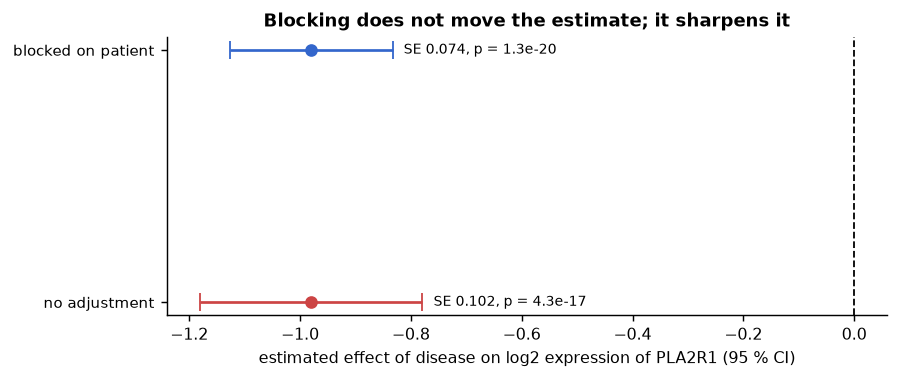

In [20]:
# One gene, analysed with and without the patient blocking factor.
expr = load_data("geo_periodontitis_expr.csv", index_col=0)
meta = load_data("geo_periodontitis_meta.csv").set_index("sample_id")
d_ids = meta.index[meta.status == "diseased"]; h_ids = meta.index[meta.status == "healthy"]
d_ids = meta.loc[d_ids].sort_values("patient_id").index; h_ids = meta.loc[h_ids].sort_values("patient_id").index
GENE = "PLA2R1"
long = pd.DataFrame({
    "y": np.concatenate([expr.loc[GENE, d_ids].to_numpy(float), expr.loc[GENE, h_ids].to_numpy(float)]),
    "diseased": np.r_[np.ones(len(d_ids)), np.zeros(len(h_ids))],
    "patient": np.r_[meta.loc[d_ids, "patient_id"].to_numpy(), meta.loc[h_ids, "patient_id"].to_numpy()]})
m_plain = smf.ols("y ~ diseased", data=long).fit()
m_block = smf.ols("y ~ diseased + C(patient)", data=long).fit()
fig, ax = plt.subplots(figsize=(7.0, 3.0))
for i, (lab, mdl, c) in enumerate([("no adjustment", m_plain, "#c44"), ("blocked on patient", m_block, "#36c")]):
    ci = mdl.conf_int().loc["diseased"]
    ax.errorbar(mdl.params["diseased"], i, xerr=[[mdl.params["diseased"] - ci[0]], [ci[1] - mdl.params["diseased"]]],
                fmt="o", color=c, capsize=5)
    ax.text(ci[1] + 0.02, i, "SE %.3f, p = %.1e" % (mdl.bse["diseased"], mdl.pvalues["diseased"]), va="center",
            fontsize=8)
ax.axvline(0, color="k", ls="--", lw=1)
ax.set_yticks([0, 1]); ax.set_yticklabels(["no adjustment", "blocked on patient"], fontsize=8.5)
ax.set_xlabel("estimated effect of disease on log2 expression of %s (95 %% CI)" % GENE)
ax.set_title("Blocking does not move the estimate; it sharpens it")
fig.tight_layout()
print("unadjusted : beta = %+.3f, SE = %.3f, p = %.2e, R2 = %.3f"
      % (m_plain.params["diseased"], m_plain.bse["diseased"], m_plain.pvalues["diseased"], m_plain.rsquared))
print("blocked    : beta = %+.3f, SE = %.3f, p = %.2e, R2 = %.3f (%d extra parameters)"
      % (m_block.params["diseased"], m_block.bse["diseased"], m_block.pvalues["diseased"], m_block.rsquared,
         int(m_block.df_model - m_plain.df_model)))
print("AIC: %.1f (unadjusted) vs %.1f (blocked) | BIC: %.1f vs %.1f"
      % (m_plain.aic, m_block.aic, m_plain.bic, m_block.bic))

<p class="caption"><b>Figure 11.</b> The estimated effect of disease on the expression of one gene, with and without the patient blocking factor. The point estimate is identical to three decimals — because the design is balanced, every patient contributing exactly one sample of each type — while the standard error falls by about a quarter and the interval narrows accordingly. Blocking in a balanced design buys precision, not a different answer; in an <em>unbalanced</em> design it would also move the estimate, and that movement is what "adjusting for a confounder" means.</p>

The AIC and BIC printed below the figure disagree sharply about whether the blocking factor is worth its 68 extra parameters: AIC prefers the blocked model, BIC prefers the simple one. Neither is wrong — they answer different questions, and the design, not an information criterion, decides here. The samples are paired by construction, so the blocked model is the correct one regardless of what a criterion says.

<div class="box warn"><h4>Fixed effects or mixed models?</h4>
<p>Adding 68 patient dummies spends 68 degrees of freedom to estimate nuisance parameters nobody will read. The economical alternative is a <strong>mixed-effects model</strong>, which treats the patient effect as a random draw from a distribution and estimates its variance rather than its 69 values. For a balanced paired design the two give nearly the same answer for the coefficient of interest; for unbalanced designs with many groups and few observations each — exactly the structure of compounds nested in assays, or frames nested in replicas — the mixed model is substantially better, and it is the natural frequentist sibling of the hierarchical Bayesian model in <a href="../U10_Bayesian/index.html">Unit 10</a>. In statsmodels it is <code>smf.mixedlm("y ~ diseased", data=long, groups=long["patient"])</code>.</p></div>

## 12. Explaining or predicting?

Two cultures use the same equation for different purposes<sup class="c"><a href="#r26">[26]</a></sup><sup class="c"><a href="#r27">[27]</a></sup>:

- **Explanatory modelling** asks what the coefficients are. It needs correct specification, interpretable predictors, attention to collinearity and confounding, and intervals on the coefficients. Its failure mode is a confident causal story from an observational fit — a regression coefficient is an association, and no amount of adjustment turns an observational association into a cause<sup class="c"><a href="#r31">[31]</a></sup>.
- **Predictive modelling** asks how accurate predictions are on new data. It tolerates collinearity, black-box features and uninterpretable parameters, and is judged only by held-out performance. Its failure mode is a model that predicts well and is read as if it explained something.

The same dataset answers the two questions differently, which this unit has demonstrated twice. The eleven-descriptor model fitted within a congeneric series (§3) is an explanatory attempt, and it says there is nothing to explain with whole-molecule descriptors. The 200-descriptor penalised model (§9) is a predictive attempt, and it reaches a cross-validated R² around 0.3 — modest but real, and the *selected descriptors are not a chemical conclusion* (§9.1). Writing the first result in a paper as if the second had supported it is the single most common misuse of QSAR.

<div class="box key"><h4>Decide before you fit</h4>
<p>Write one sentence stating whether the model exists to produce a number for new compounds or to support a statement about which properties matter. The decision determines the descriptor set, the validation protocol, the diagnostics that matter, and what may be written in the abstract. If the answer is "both", build two models and report them separately.</p></div>

<div class="box bridge"><h4>Bridge</h4>
<p>This unit completes the statistics block that began with <a href="../U7_Estimation/index.html">Unit 7</a> (intervals, bootstrap, noise floor) and <a href="../U8_Hypothesis_Testing/index.html">Unit 8</a> (tests, effect sizes, multiplicity, power); <a href="../U10_Bayesian/index.html">Unit 10</a> re-fits the hierarchical version of §11 with explicit priors. Forward, <a href="../U11_Supervised_Workflow/index.html">Unit 11</a> turns the regularised fit of §9 into a leakage-free pipeline, <a href="../U12_Validation/index.html">Unit 12</a> supplies the split taxonomy and y-randomisation that §7 previewed, <a href="../U13_Features_Dimensionality/index.html">Unit 13</a> develops descriptor selection beyond the lasso, <a href="../U16_Interpretability/index.html">Unit 16</a> asks what a non-linear model learned, and <a href="../U21_Omics/index.html">Unit 21</a> fits one linear model per gene with moderated variances<sup class="c"><a href="#r28">[28]</a></sup>. In the sister courses, the cheminformatics unit on <a href="../../Cheminformatics/U12_Classical_QSAR/index.html">classical QSAR</a> covers the chemistry of Hansch analysis and its substituent constants, the unit on <a href="../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">descriptors and fingerprints</a> explains what the 200 columns of §9 contain, and the AI course's <a href="../../BGM411/Python/index.html">regression sessions</a> derive the same estimators from the machine-learning side.</p></div>

## 13. Summary

You should be able to explain, without notes:

- the linear model's four assumptions in order of importance, and which diagnostic detects each;
- how to compute OLS from the normal equations and where the standard error of a coefficient comes from;
- how to read a regression table in the right order: F test and R² first, coefficients last;
- what residual, QQ, scale–location and leverage plots each detect, and the difference between leverage and influence;
- what a variance inflation factor measures, why a constant descriptor inside a congeneric series must be removed, and the three responses to collinearity;
- that ANOVA is a linear model with categorical predictors, and what an interaction term estimates;
- why R² of 0.6 on 33 compounds with 11 descriptors can be mostly chance, and how y-randomisation quantifies it;
- how to interpret a logistic coefficient as an odds ratio, how to recognise separation, and why a well-ranking model can be badly calibrated;
- how ridge, lasso and elastic net trade bias for variance, why unpenalised OLS can have negative cross-validated R², and why lasso selection must be checked for stability;
- when to use adjusted R², AIC, BIC and the likelihood-ratio test, and what blocking buys in a paired design;
- the difference between explanatory and predictive modelling, and why the choice must be made before fitting.

## 14. Self-assessment

<details><summary>1. Your R² rises every time you add a descriptor. Is the model improving?</summary>No. R² cannot decrease when a predictor is added, even a column of random numbers, because the least-squares fit can always set the new coefficient to zero and do no worse. Use adjusted R², AIC or cross-validated R², all of which can go down.</details>

<details><summary>2. A coefficient has a huge standard error and a VIF of 40. What is happening and what do you do?</summary>That descriptor is nearly a linear combination of the others, so the data cannot separate their contributions. Drop or merge the redundant descriptors on chemical grounds, or regularise. Do not conclude that the descriptor is unimportant — collinearity inflates the standard error without changing the predictions.</details>

<details><summary>3. What does leverage measure, and how does it differ from influence?</summary>Leverage measures how far a compound's predictor values are from the centre of the descriptor cloud; it depends on X only. Influence (Cook's distance) measures how much the fitted model changes if that compound is removed, combining leverage with the size of its residual. A high-leverage compound that fits well has little influence.</details>

<details><summary>4. Your QSAR on 25 compounds with 8 descriptors gives R² = 0.75. What must you report alongside it?</summary>The adjusted R² (which falls sharply with 8 parameters on 25 points), a y-randomisation control with the distribution of scrambled R², and an external or cross-validated estimate. With 3 compounds per descriptor the expected R² under pure noise is already about 0.33.</details>

<details><summary>5. Why is the ring count constant inside a congeneric series, and why does that matter?</summary>Because a congeneric series is defined by a shared scaffold, and the rings are part of the scaffold. A constant column carries no information, is collinear with the intercept, and makes the design matrix singular; it must be dropped before fitting, and its presence is a sign that the descriptor set was chosen for a different dataset.</details>

<details><summary>6. Interpret a logistic coefficient of 0.83 on a standardised descriptor.</summary>The odds of being active multiply by exp(0.83) ≈ 2.3 for each one-standard-deviation increase in that descriptor, holding the others fixed. Report the odds ratio with its confidence interval, not the coefficient, and state that "holding the others fixed" is an arithmetic statement about the model, not a claim that the descriptor can be changed independently in a real molecule.</details>

<details><summary>7. Your logistic model reports a coefficient of 48 with a standard error of 1,200. What happened?</summary>Separation: some predictor or combination of predictors perfectly classifies the outcome, so the likelihood has no finite maximum. Check whether the classes are disjoint on that predictor, and use a penalised or Firth-corrected fit. Note that scikit-learn hides this by regularising by default.</details>

<details><summary>8. Model A has AUC 0.85 and Brier 0.22; model B has AUC 0.85 and Brier 0.14. Which do you deploy?</summary>B, if the predicted probabilities are used for anything — a cost calculation, a triage threshold, a screening budget. The two models rank compounds identically; B's probabilities are closer to the observed frequencies. If only the ranking is used, the choice is indifferent.</details>

<details><summary>9. Why can unpenalised OLS have a negative cross-validated R²?</summary>Because cross-validated R² is computed on data the model has not seen, and a model with 200 correlated predictors fits the noise of the training set so closely that its predictions on new compounds are worse than simply predicting the training mean. Negative CV R² is the signature of over-fitting, and it is invisible if only the training R² is reported.</details>

<details><summary>10. The lasso selected 62 descriptors. Can you write "these 63 descriptors determine potency"?</summary>No. Repeat the fit on bootstrap resamples: in our experiment only about thirty descriptors were selected in at least 80 % of resamples, while over a hundred appeared in a fifth or fewer. Report selection frequencies, and remember that when descriptors are correlated, the lasso picks one of them nearly arbitrarily.</details>

<details><summary>11. AIC prefers the complex model and BIC the simple one. Which do you believe?</summary>Neither automatically — they target different things (AIC approximates predictive loss, BIC approximates posterior model probability with a log n penalty) and disagreement simply means the extra parameters are worth about as much as they cost. Decide with the design and the scientific question; in a paired design, the blocking factor stays in the model whatever BIC says.</details>

<details><summary>12. What does blocking on patient do to the estimate and to its standard error in a balanced paired design?</summary>It leaves the point estimate essentially unchanged and reduces the standard error, because between-patient variation is removed from the residual. In an unbalanced design it would also shift the estimate, which is the sense in which it "adjusts for" the patient.</details>

## Glossary

<dl class="gloss">
<dt>Adjusted R²</dt><dd>R² penalised for the number of predictors; unlike R² it can decrease when a predictor is added.</dd>
<dt>AIC / BIC</dt><dd>Information criteria balancing fit against complexity, with penalties of 2 and log(n) per parameter; comparable only across models on identical data.</dd>
<dt>Blocking</dt><dd>Including the identity of the experimental unit (patient, batch, plate) as a factor, removing its variation from the residual.</dd>
<dt>Calibration</dt><dd>Agreement between predicted probabilities and observed frequencies; measured by a reliability curve and the Brier score.</dd>
<dt>Chance correlation</dt><dd>Apparent fit arising from too many descriptors on too few compounds; quantified by response randomisation.</dd>
<dt>Confounder</dt><dd>A variable associated with both predictor and response that can create or mask an apparent effect.</dd>
<dt>Cook's distance</dt><dd>Influence measure combining leverage and residual size; the change in the fit when one observation is deleted.</dd>
<dt>Elastic net</dt><dd>Penalty mixing L1 and L2; keeps correlated predictors together instead of choosing one.</dd>
<dt>Hansch analysis</dt><dd>Classical QSAR: a linear model of potency in physicochemical substituent properties within a congeneric series.</dd>
<dt>Interaction</dt><dd>A product term letting the slope on one predictor depend on another.</dd>
<dt>Lasso</dt><dd>L1-penalised regression; shrinks some coefficients exactly to zero, performing selection.</dd>
<dt>Leverage</dt><dd>How far an observation's predictors lie from their centroid; the diagonal of the hat matrix.</dd>
<dt>Likelihood-ratio test</dt><dd>Chi-square test comparing two nested models by twice their difference in log-likelihood.</dd>
<dt>Logistic regression</dt><dd>Linear model for the log-odds of a binary outcome; coefficients exponentiate to odds ratios.</dd>
<dt>Multicollinearity</dt><dd>Near-linear dependence among predictors; inflates coefficient variances without harming predictions.</dd>
<dt>Normal equations</dt><dd>XᵀXβ = Xᵀy, whose solution is the least-squares estimate.</dd>
<dt>Odds ratio</dt><dd>exp(coefficient) in a logistic model; the multiplicative change in odds per unit of the predictor.</dd>
<dt>Ridge regression</dt><dd>L2-penalised regression; shrinks all coefficients smoothly and keeps every predictor.</dd>
<dt>Separation</dt><dd>A predictor combination perfectly classifying the outcome, so the logistic likelihood has no finite maximum.</dd>
<dt>Stability selection</dt><dd>Assessing which predictors a selection method keeps across resamples of the data.</dd>
<dt>VIF</dt><dd>Variance inflation factor, 1/(1 − R²ⱼ); the factor by which collinearity inflates a coefficient's variance.</dd>
<dt>y-randomisation</dt><dd>Permuting the response and refitting, to obtain the null distribution of a goodness-of-fit statistic.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Seabold S, Perktold J. Statsmodels: econometric and statistical modeling with Python. In: <em>Proc. 9th Python in Science Conf.</em> 2010:92-96. <a href="https://doi.org/10.25080/Majora-92bf1922-011">doi:10.25080/Majora-92bf1922-011</a></li>
<li id="r2">Hansch C, Maloney PP, Fujita T, Muir RM. Correlation of biological activity of phenoxyacetic acids with Hammett substituent constants and partition coefficients. <em>Nature</em>. 1962;194:178-180. <a href="https://doi.org/10.1038/194178b0">doi:10.1038/194178b0</a></li>
<li id="r3">Hansch C, Fujita T. p-sigma-pi analysis. A method for the correlation of biological activity and chemical structure. <em>J Am Chem Soc</em>. 1964;86(8):1616-1626. <a href="https://doi.org/10.1021/ja01062a035">doi:10.1021/ja01062a035</a></li>
<li id="r4">Topliss JG, Costello RJ. Chance correlations in structure-activity studies using multiple regression analysis. <em>J Med Chem</em>. 1972;15(10):1066-1068. <a href="https://doi.org/10.1021/jm00280a017">doi:10.1021/jm00280a017</a></li>
<li id="r5">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r6">Cook RD. Detection of influential observation in linear regression. <em>Technometrics</em>. 1977;19(1):15-18. <a href="https://doi.org/10.1080/00401706.1977.10489493">doi:10.1080/00401706.1977.10489493</a></li>
<li id="r7">O'Brien RM. A caution regarding rules of thumb for variance inflation factors. <em>Qual Quant</em>. 2007;41:673-690. <a href="https://doi.org/10.1007/s11135-006-9018-6">doi:10.1007/s11135-006-9018-6</a></li>
<li id="r8">Dormann CF, Elith J, Bacher S, et al. Collinearity: a review of methods to deal with it and a simulation study evaluating their performance. <em>Ecography</em>. 2013;36(1):27-46. <a href="https://doi.org/10.1111/j.1600-0587.2012.07348.x">doi:10.1111/j.1600-0587.2012.07348.x</a></li>
<li id="r9">Krzywinski M, Altman N. Analysis of variance and blocking. <em>Nat Methods</em>. 2014;11:699-700. <a href="https://doi.org/10.1038/nmeth.3005">doi:10.1038/nmeth.3005</a></li>
<li id="r10">Golbraikh A, Tropsha A. Beware of q2! <em>J Mol Graph Model</em>. 2002;20(4):269-276. <a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r11">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6-7):476-488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r12">Gramatica P. Principles of QSAR models validation: internal and external. <em>QSAR Comb Sci</em>. 2007;26(5):694-701. <a href="https://doi.org/10.1002/qsar.200610151">doi:10.1002/qsar.200610151</a></li>
<li id="r13">Hawkins DM. The problem of overfitting. <em>J Chem Inf Comput Sci</em>. 2004;44(1):1-12. <a href="https://doi.org/10.1021/ci0342472">doi:10.1021/ci0342472</a></li>
<li id="r14">Peduzzi P, Concato J, Kemper E, Holford TR, Feinstein AR. A simulation study of the number of events per variable in logistic regression analysis. <em>J Clin Epidemiol</em>. 1996;49(12):1373-1379. <a href="https://doi.org/10.1016/S0895-4356(96)00236-3">doi:10.1016/S0895-4356(96)00236-3</a></li>
<li id="r15">Vittinghoff E, McCulloch CE. Relaxing the rule of ten events per variable in logistic and Cox regression. <em>Am J Epidemiol</em>. 2007;165(6):710-718. <a href="https://doi.org/10.1093/aje/kwk052">doi:10.1093/aje/kwk052</a></li>
<li id="r16">Albert A, Anderson JA. On the existence of maximum likelihood estimates in logistic regression models. <em>Biometrika</em>. 1984;71(1):1-10. <a href="https://doi.org/10.1093/biomet/71.1.1">doi:10.1093/biomet/71.1.1</a></li>
<li id="r17">Firth D. Bias reduction of maximum likelihood estimates. <em>Biometrika</em>. 1993;80(1):27-38. <a href="https://doi.org/10.1093/biomet/80.1.27">doi:10.1093/biomet/80.1.27</a></li>
<li id="r18">Van Calster B, McLernon DJ, van Smeden M, Wynants L, Steyerberg EW. Calibration: the Achilles heel of predictive analytics. <em>BMC Med</em>. 2019;17:230. <a href="https://doi.org/10.1186/s12916-019-1466-7">doi:10.1186/s12916-019-1466-7</a></li>
<li id="r19">Hoerl AE, Kennard RW. Ridge regression: biased estimation for nonorthogonal problems. <em>Technometrics</em>. 1970;12(1):55-67. <a href="https://doi.org/10.1080/00401706.1970.10488634">doi:10.1080/00401706.1970.10488634</a></li>
<li id="r20">Tibshirani R. Regression shrinkage and selection via the lasso. <em>J R Stat Soc B</em>. 1996;58(1):267-288. <a href="https://doi.org/10.1111/j.2517-6161.1996.tb02080.x">doi:10.1111/j.2517-6161.1996.tb02080.x</a></li>
<li id="r21">Zou H, Hastie T. Regularization and variable selection via the elastic net. <em>J R Stat Soc B</em>. 2005;67(2):301-320. <a href="https://doi.org/10.1111/j.1467-9868.2005.00503.x">doi:10.1111/j.1467-9868.2005.00503.x</a></li>
<li id="r22">Meinshausen N, Bühlmann P. Stability selection. <em>J R Stat Soc B</em>. 2010;72(4):417-473. <a href="https://doi.org/10.1111/j.1467-9868.2010.00740.x">doi:10.1111/j.1467-9868.2010.00740.x</a></li>
<li id="r23">Akaike H. A new look at the statistical model identification. <em>IEEE Trans Automat Contr</em>. 1974;19(6):716-723. <a href="https://doi.org/10.1109/TAC.1974.1100705">doi:10.1109/TAC.1974.1100705</a></li>
<li id="r24">Schwarz G. Estimating the dimension of a model. <em>Ann Stat</em>. 1978;6(2):461-464. <a href="https://doi.org/10.1214/aos/1176344136">doi:10.1214/aos/1176344136</a></li>
<li id="r25">Papapanou PN, Behle JH, Kebschull M, et al. Subgingival bacterial colonization profiles correlate with gingival tissue gene expression. <em>BMC Microbiol</em>. 2009;9:221. <a href="https://doi.org/10.1186/1471-2180-9-221">doi:10.1186/1471-2180-9-221</a></li>
<li id="r26">Breiman L. Statistical modeling: the two cultures. <em>Stat Sci</em>. 2001;16(3):199-231. <a href="https://doi.org/10.1214/ss/1009213726">doi:10.1214/ss/1009213726</a></li>
<li id="r27">Shmueli G. To explain or to predict? <em>Stat Sci</em>. 2010;25(3):289-310. <a href="https://doi.org/10.1214/10-STS330">doi:10.1214/10-STS330</a></li>
<li id="r28">Smyth GK. Linear models and empirical Bayes methods for assessing differential expression in microarray experiments. <em>Stat Appl Genet Mol Biol</em>. 2004;3:Article 3. <a href="https://doi.org/10.2202/1544-6115.1027">doi:10.2202/1544-6115.1027</a></li>
<li id="r29">Cramer RD, Patterson DE, Bunce JD. Comparative molecular field analysis (CoMFA). 1. Effect of shape on binding of steroids to carrier proteins. <em>J Am Chem Soc</em>. 1988;110(18):5959-5967. <a href="https://doi.org/10.1021/ja00226a005">doi:10.1021/ja00226a005</a></li>
<li id="r30">Krzywinski M, Altman N. Multiple linear regression. <em>Nat Methods</em>. 2015;12:1103-1104. <a href="https://doi.org/10.1038/nmeth.3665">doi:10.1038/nmeth.3665</a></li>
<li id="r31">Altman N, Krzywinski M. Association, correlation and causation. <em>Nat Methods</em>. 2015;12:899-900. <a href="https://doi.org/10.1038/nmeth.3587">doi:10.1038/nmeth.3587</a></li>
<li id="r32">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r33">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data - a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023 (free PDF). — Chapters 3, 4 and 6 are this unit at an introductory pace.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009 (free PDF). — Chapters 3–4 for the geometry of ridge and lasso.</li>
<li>Gelman A, Hill J, Vehtari A. <em>Regression and Other Stories</em>. Cambridge University Press; 2020. — The best modern treatment of interpreting regression coefficients honestly.</li>
<li>Harrell FE. <em>Regression Modeling Strategies</em>. 2nd ed. Springer; 2015. — Calibration, degrees-of-freedom budgeting and validation for clinical models.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>statsmodels user guide, "Linear Regression" and "Regression Diagnostics": <a href="https://www.statsmodels.org/stable/regression.html">statsmodels.org/stable/regression.html</a>.</li>
<li>scikit-learn user guide, "Linear Models" (ridge, lasso, elastic net, logistic regression): <a href="https://scikit-learn.org/stable/modules/linear_model.html">scikit-learn.org/stable/modules/linear_model.html</a>.</li>
<li>TeachOpenCADD talktorial on ligand-based screening and classical QSAR: <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters), posts on descriptor collinearity and on reading QSAR papers critically: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>